# Adult Income Classification

### Exploratory Data Analysis • Statistical Analysis • Machine Learning • Model Optimisation

**Dataset:** `data/adult_income_classification_dataset.csv` — 45,222 census-income observations and 14 columns.

**Research question:** How accurately can employment, education and other census-derived characteristics distinguish between historical annual-income categories of **≤US$50,000** and **>US$50,000**?

**Scope:** Exploratory analysis of historical U.S. census-derived data, followed by comparative supervised classification. Income categories are nominal historical values and are not adjusted for inflation. This analysis is an educational and research exercise; it is **not appropriate for hiring, lending, welfare eligibility or other consequential decisions concerning individuals**. Sensitive demographic variables are analysed descriptively and used for error audits, not included in model training. Indirect bias may nevertheless remain.

**Analytical workflow:** Data audit → descriptive and categorical analysis → feature preparation → group-aware holdout → supervised model development → model comparison → clustering → optimisation and model interpretation → subgroup diagnostics → conclusions and future objectives.


## 1. Environment and reproducibility

We use a fixed random seed, documented dependencies and a repository-relative CSV path to support reproducible execution.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    silhouette_score, roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.inspection import permutation_importance

SEED=42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns',40)
DATA_CANDIDATES=[Path('data/adult_income_classification_dataset.csv'), Path('../data/adult_income_classification_dataset.csv'), Path('adult_income_classification_dataset.csv')]
DATA_PATH=next((p for p in DATA_CANDIDATES if p.is_file()),None)
if DATA_PATH is None:
    raise FileNotFoundError('Could not find data/adult_income_classification_dataset.csv. Please see README.md.')
print('Data file:',DATA_PATH)

Data file: data/adult_income_classification_dataset.csv


### 1.1 Dataset interpretation

The target variable, `income`, divides observations into two historical annual-income groups: `<=50K` and `>50K`. This is a **binary classification task**, not a prediction of an exact salary. Variables describing demographic background, education and employment are analysed as historical associations, not as evidence of causation.


In [2]:
df=pd.read_csv(DATA_PATH,skipinitialspace=True,na_values=['?',' ?'])
df.columns=df.columns.str.strip()
for col in df.select_dtypes(include='object'):
    df[col]=df[col].str.strip()
expected=['age','workclass','education_level','education-num','marital-status','occupation',
          'relationship','race','sex','capital-gain','capital-loss','hours-per-week',
          'native-country','income']
assert list(df.columns)==expected, f'Dataset columns are not the expected schema: {df.columns.tolist()}'
assert set(df['income'].unique())=={'<=50K','>50K'}, 'Unexpected target labels'
print(f'Dataset dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Dataset dimensions: 45,222 rows × 14 columns


,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K


### 1.2 Dataset variables

The dataset contains socio-demographic and employment descriptors, capital gains and losses, weekly working hours, and the target label. `education_level` and `education-num` describe related education information; the numeric field is kept in the model, while both are explored during EDA. `race` and `sex` are reserved for descriptive and error-rate audits rather than model input.

In [3]:
schema=pd.DataFrame({'column':df.columns,'type':df.dtypes.astype(str).values,
    'missing_count':df.isna().sum().values,'distinct_values':df.nunique(dropna=True).values})
display(schema)

,column,type,missing_count,distinct_values
0,age,int64,0,74
1,workclass,object,0,7
2,education_level,object,0,16
3,education-num,float64,0,16
4,marital-status,object,0,7
5,occupation,object,0,14
6,relationship,object,0,6
7,race,object,0,5
8,sex,object,0,2
9,capital-gain,float64,0,121


### 1.3 Data completeness and data types

In [4]:
print('Nulls by variable:')
display(df.isna().sum().to_frame('missing'))
print('Data types:')
print(df.dtypes.to_string())

Nulls by variable:


,missing
age,0
workclass,0
education_level,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0
capital-gain,0


Data types:
age                  int64
workclass           object
education_level     object
education-num      float64
marital-status      object
occupation          object
relationship        object
race                object
sex                 object
capital-gain       float64
capital-loss       float64
hours-per-week     float64
native-country      object
income              object


The dataset contains no conventional missing values. This is confirmed in the data-quality summary below.

In [5]:
print('Exact duplicate complete records:', int(df.duplicated().sum()))
print('Duplicate percentage: {:.2f}%'.format(100*df.duplicated().mean()))
print('Duplicate feature rows (target ignored):', int(df.drop(columns='income').duplicated().sum()))
print('Duplicate input patterns do not necessarily mean invalid observations.')

Exact duplicate complete records: 5982
Duplicate percentage: 13.23%
Duplicate feature rows (target ignored): 6993
Duplicate input patterns do not necessarily mean invalid observations.


We retain all supplied rows. Records can share identical reported characteristics, so deleting duplicates could also discard valid observations. Later, a **group-aware split** keeps identical model inputs within one subset to reduce overly optimistic holdout estimates.

In [6]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45222.0,NaN,NaN,NaN,38.547941,13.21787,17.0,28.0,37.0,47.0,90.0
workclass,45222,7,Private,33307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,45222,16,HS-grad,14783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,45222.0,NaN,NaN,NaN,10.11846,2.552881,1.0,9.0,10.0,13.0,16.0
marital-status,45222,7,Married-civ-spouse,21055,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,45222,14,Craft-repair,6020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,45222,6,Husband,18666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,45222,5,White,38903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,45222,2,Male,30527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capital-gain,45222.0,NaN,NaN,NaN,1101.430344,7506.430084,0.0,0.0,0.0,0.0,99999.0


### 1.4 Target distribution and majority-class baseline

,records,share_percent
income,,
<=50K,34014,75.22
>50K,11208,24.78


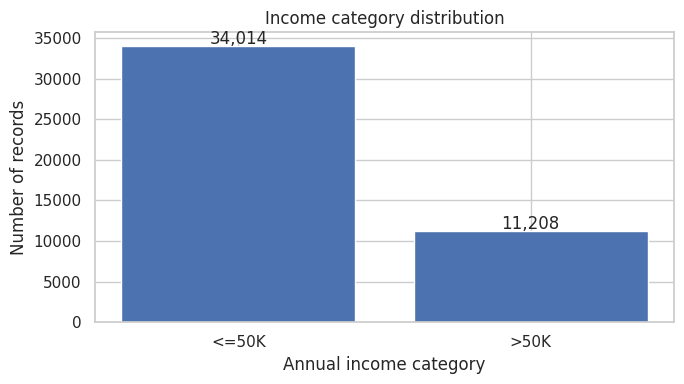

In [7]:
class_counts=df['income'].value_counts().reindex(['<=50K','>50K'])
class_rates=(class_counts/len(df)*100).round(2)
display(pd.DataFrame({'records':class_counts,'share_percent':class_rates}))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(class_counts.index,class_counts.values)
ax.set(title='Income category distribution',ylabel='Number of records',xlabel='Annual income category')
for i,n in enumerate(class_counts.values):ax.text(i,n+250,f'{n:,}',ha='center')
plt.tight_layout();plt.show()

The majority of the records fall in the at-most-$50K class. Accuracy alone can be misleading, so subsequent model comparisons emphasise **F1, recall, balanced accuracy, ROC-AUC and average precision** for the higher-income class.

## 2. Descriptive analysis — numerical attributes

We examine numeric distributions, outliers, skewness and their descriptive relationships with the income labels.

### 2.1 Age

Descriptive summaries are calculated on the provided 45,222 records. These associations do not establish causation or justify predictions about individuals.

In [8]:
print('Summary for age')
display(df['age'].describe(percentiles=[.05,.25,.5,.75,.95,.99]).to_frame('value'))
print('Zero values:',int((df['age']==0).sum()))

Summary for age


,value
count,45222.000000
mean,38.547941
std,13.217870
min,17.000000
5%,20.000000
25%,28.000000
50%,37.000000
75%,47.000000
95%,62.000000
99%,73.000000


Zero values: 0


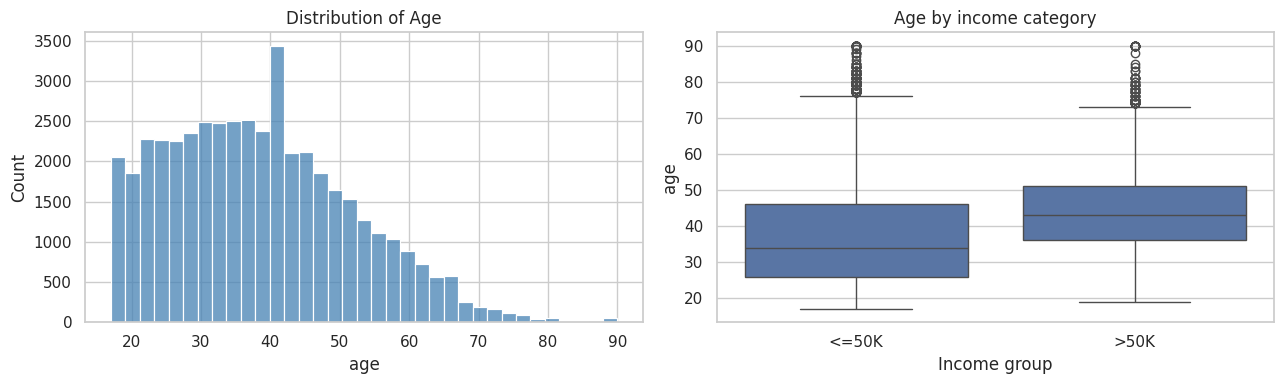

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df['age'],bins=35,ax=axes[0],color='steelblue')
axes[0].set(title='Distribution of Age',xlabel='age')
sns.boxplot(data=df,x='income',y='age',ax=axes[1])
axes[1].set(title='Age by income category',xlabel='Income group')
plt.tight_layout();plt.show()

In [10]:
table=df.groupby('income')['age'].agg(['count','mean','median','std']).round(2)
display(table)

,count,mean,median,std
income,,,,
<=50K,34014,36.75,34.0,13.56
>50K,11208,44.01,43.0,10.34


**Interpretation note:** The groups may have different `age` distributions, but the comparison is observational. Extremely skewed values (especially capital gains/losses) require care when interpreting means or fitting linear models.

### 2.2 Education years / numerical code

Descriptive summaries are calculated on the provided 45,222 records. These associations do not establish causation or justify predictions about individuals.

In [11]:
print('Summary for education-num')
display(df['education-num'].describe(percentiles=[.05,.25,.5,.75,.95,.99]).to_frame('value'))
print('Zero values:',int((df['education-num']==0).sum()))

Summary for education-num


,value
count,45222.000000
mean,10.118460
std,2.552881
min,1.000000
5%,6.000000
25%,9.000000
50%,10.000000
75%,13.000000
95%,14.000000
99%,16.000000


Zero values: 0


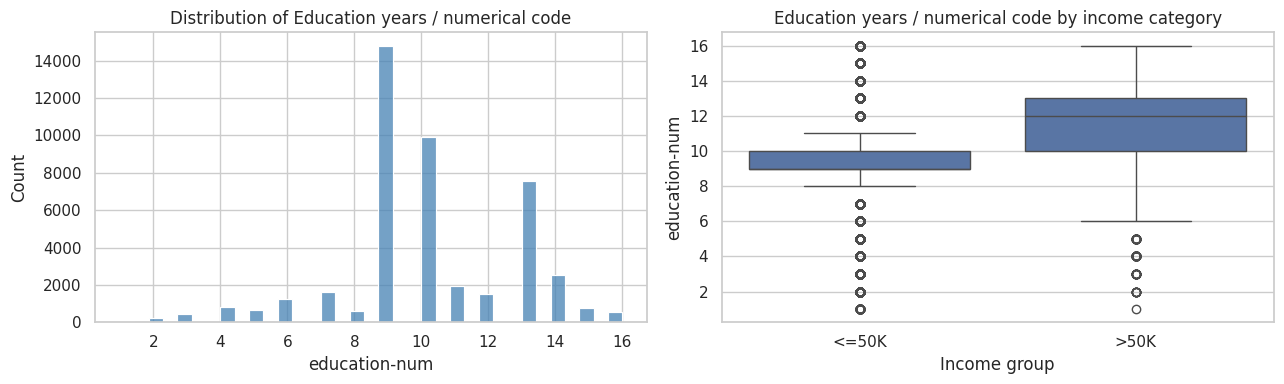

In [12]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df['education-num'],bins=35,ax=axes[0],color='steelblue')
axes[0].set(title='Distribution of Education years / numerical code',xlabel='education-num')
sns.boxplot(data=df,x='income',y='education-num',ax=axes[1])
axes[1].set(title='Education years / numerical code by income category',xlabel='Income group')
plt.tight_layout();plt.show()

In [13]:
table=df.groupby('income')['education-num'].agg(['count','mean','median','std']).round(2)
display(table)

,count,mean,median,std
income,,,,
<=50K,34014,9.63,9.0,2.42
>50K,11208,11.60,12.0,2.37


**Interpretation note:** The groups may have different `education-num` distributions, but the comparison is observational. Extremely skewed values (especially capital gains/losses) require care when interpreting means or fitting linear models.

### 2.3 Capital gain

Descriptive summaries are calculated on the provided 45,222 records. These associations do not establish causation or justify predictions about individuals.

In [14]:
print('Summary for capital-gain')
display(df['capital-gain'].describe(percentiles=[.05,.25,.5,.75,.95,.99]).to_frame('value'))
print('Zero values:',int((df['capital-gain']==0).sum()))

Summary for capital-gain


,value
count,45222.000000
mean,1101.430344
std,7506.430084
min,0.000000
5%,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
95%,5013.000000
99%,15024.000000


Zero values: 41432


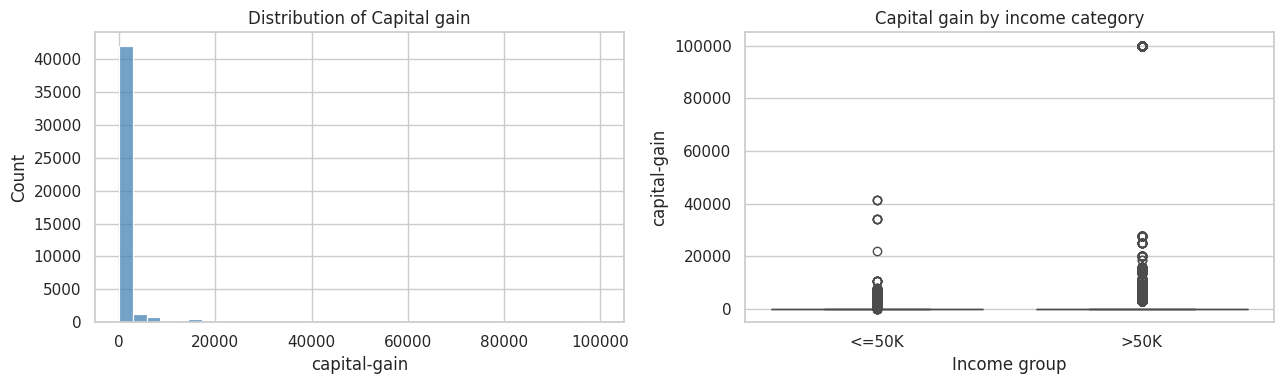

In [15]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df['capital-gain'],bins=35,ax=axes[0],color='steelblue')
axes[0].set(title='Distribution of Capital gain',xlabel='capital-gain')
sns.boxplot(data=df,x='income',y='capital-gain',ax=axes[1])
axes[1].set(title='Capital gain by income category',xlabel='Income group')
plt.tight_layout();plt.show()

In [16]:
table=df.groupby('income')['capital-gain'].agg(['count','mean','median','std']).round(2)
display(table)

,count,mean,median,std
income,,,,
<=50K,34014,149.02,0.0,927.45
>50K,11208,3991.79,0.0,14616.54


**Interpretation note:** The groups may have different `capital-gain` distributions, but the comparison is observational. Extremely skewed values (especially capital gains/losses) require care when interpreting means or fitting linear models.

### 2.4 Capital loss

Descriptive summaries are calculated on the provided 45,222 records. These associations do not establish causation or justify predictions about individuals.

In [17]:
print('Summary for capital-loss')
display(df['capital-loss'].describe(percentiles=[.05,.25,.5,.75,.95,.99]).to_frame('value'))
print('Zero values:',int((df['capital-loss']==0).sum()))

Summary for capital-loss


,value
count,45222.000000
mean,88.595418
std,404.956092
min,0.000000
5%,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
95%,0.000000
99%,1980.000000


Zero values: 43082


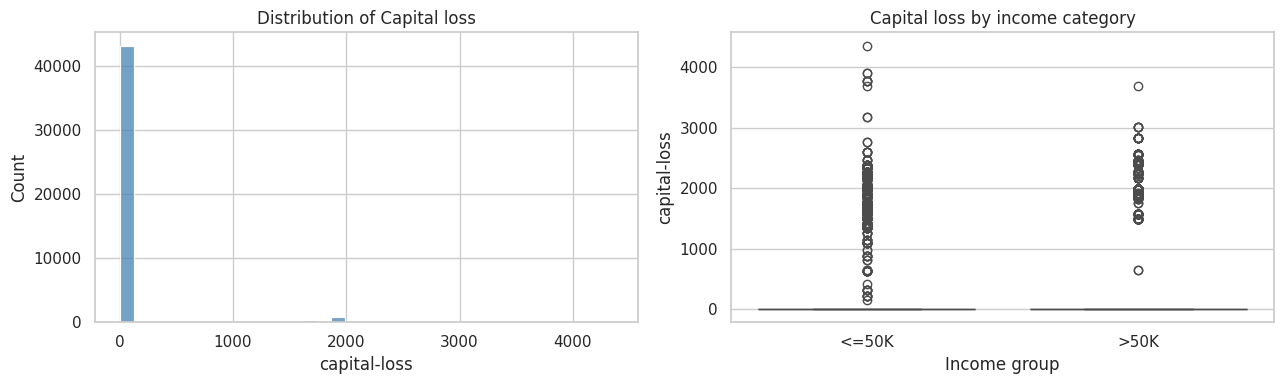

In [18]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df['capital-loss'],bins=35,ax=axes[0],color='steelblue')
axes[0].set(title='Distribution of Capital loss',xlabel='capital-loss')
sns.boxplot(data=df,x='income',y='capital-loss',ax=axes[1])
axes[1].set(title='Capital loss by income category',xlabel='Income group')
plt.tight_layout();plt.show()

In [19]:
table=df.groupby('income')['capital-loss'].agg(['count','mean','median','std']).round(2)
display(table)

,count,mean,median,std
income,,,,
<=50K,34014,54.03,0.0,312.22
>50K,11208,193.49,0.0,592.64


**Interpretation note:** The groups may have different `capital-loss` distributions, but the comparison is observational. Extremely skewed values (especially capital gains/losses) require care when interpreting means or fitting linear models.

### 2.5 Hours worked per week

Descriptive summaries are calculated on the provided 45,222 records. These associations do not establish causation or justify predictions about individuals.

In [20]:
print('Summary for hours-per-week')
display(df['hours-per-week'].describe(percentiles=[.05,.25,.5,.75,.95,.99]).to_frame('value'))
print('Zero values:',int((df['hours-per-week']==0).sum()))

Summary for hours-per-week


,value
count,45222.000000
mean,40.938017
std,12.007508
min,1.000000
5%,20.000000
25%,40.000000
50%,40.000000
75%,45.000000
95%,60.000000
99%,80.000000


Zero values: 0


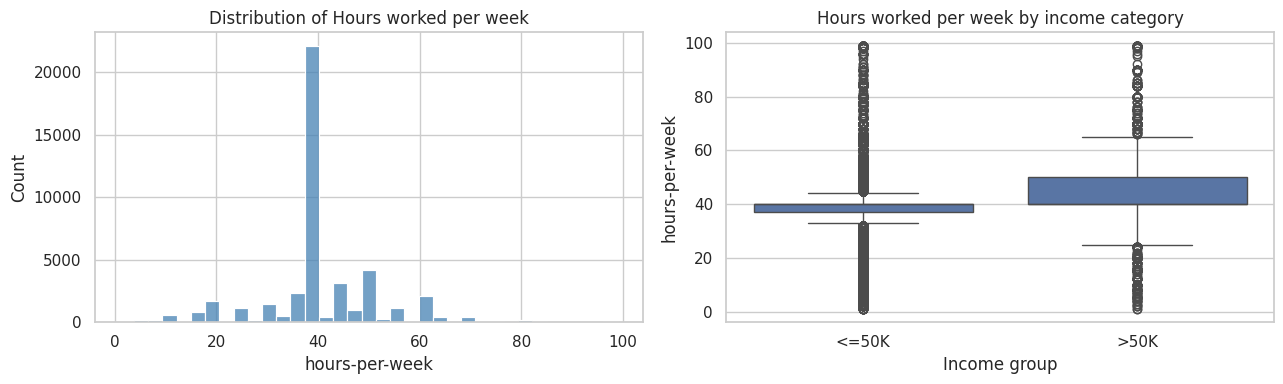

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df['hours-per-week'],bins=35,ax=axes[0],color='steelblue')
axes[0].set(title='Distribution of Hours worked per week',xlabel='hours-per-week')
sns.boxplot(data=df,x='income',y='hours-per-week',ax=axes[1])
axes[1].set(title='Hours worked per week by income category',xlabel='Income group')
plt.tight_layout();plt.show()

In [22]:
table=df.groupby('income')['hours-per-week'].agg(['count','mean','median','std']).round(2)
display(table)

,count,mean,median,std
income,,,,
<=50K,34014,39.37,40.0,11.97
>50K,11208,45.69,40.0,10.80


**Interpretation note:** The groups may have different `hours-per-week` distributions, but the comparison is observational. Extremely skewed values (especially capital gains/losses) require care when interpreting means or fitting linear models.

In [23]:
num_cols=['age','education-num','capital-gain','capital-loss','hours-per-week']

### 2.6 Numeric correlation patterns

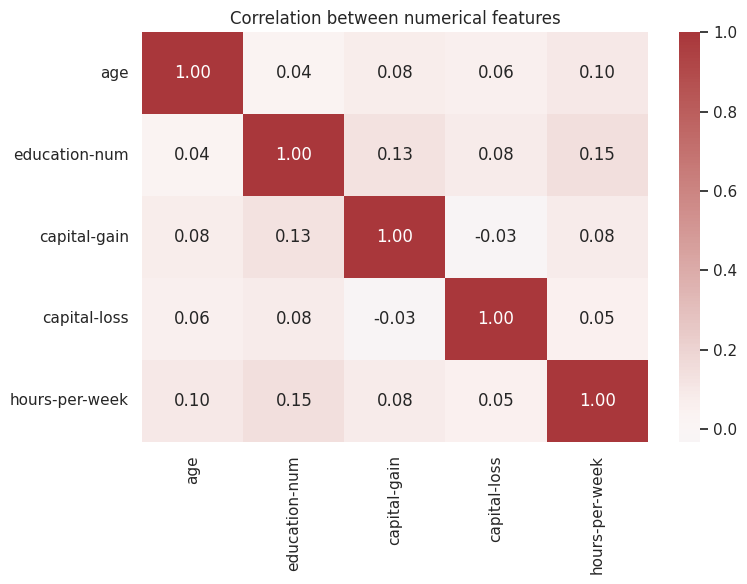

In [24]:
corr=df[num_cols].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(corr,annot=True,fmt='.2f',cmap='vlag',center=0,ax=ax)
ax.set_title('Correlation between numerical features')
plt.tight_layout();plt.show()

### 2.7 Pairwise numerical relationships

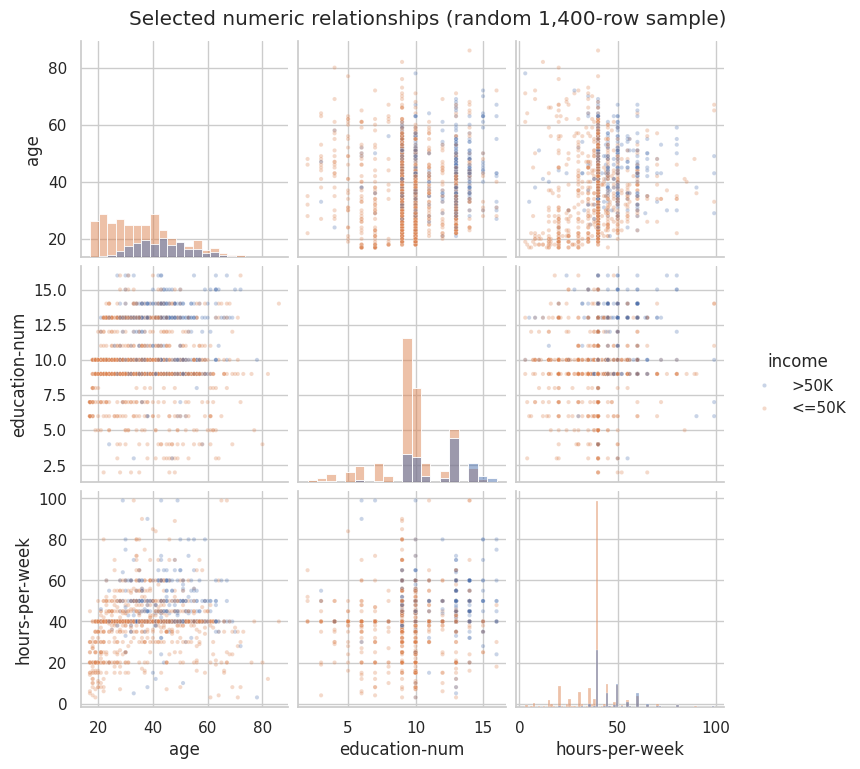

In [25]:
sample=df.sample(n=min(1400,len(df)),random_state=SEED)
plot=sns.pairplot(sample[['age','education-num','hours-per-week','income']],hue='income',diag_kind='hist',plot_kws={'alpha':.3,'s':9})
plot.fig.suptitle('Selected numeric relationships (random 1,400-row sample)',y=1.02)
plt.show()

The pairplot is sampled for readability and speed. Relationships can overlap considerably across the two income classes; no individual feature is a sufficient stand-alone predictor.

### 2.8 Capital gain / loss sparsity

,metric,zero_count,nonzero_count
0,capital-gain,41432,3790
1,capital-loss,43082,2140


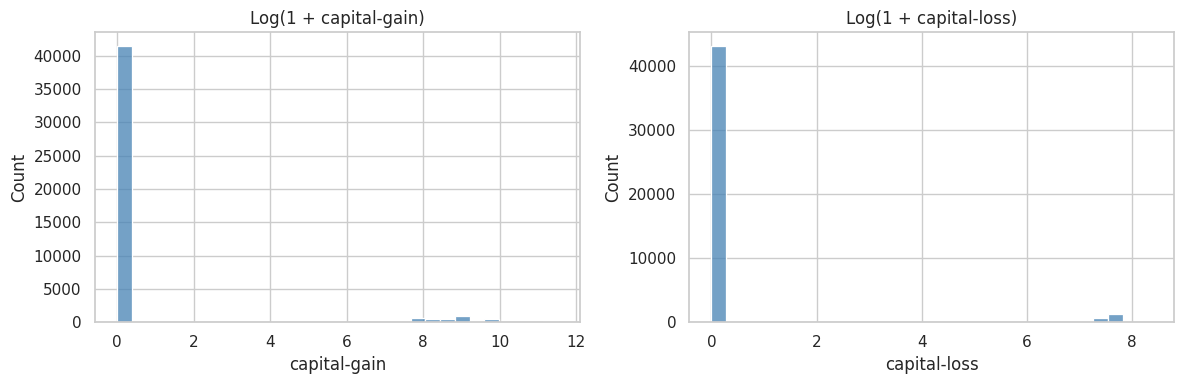

In [26]:
gain_loss=pd.DataFrame({'metric':['capital-gain','capital-loss'],'zero_count':[(df[c]==0).sum() for c in ['capital-gain','capital-loss']],
                         'nonzero_count':[(df[c]!=0).sum() for c in ['capital-gain','capital-loss']]})
display(gain_loss)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,['capital-gain','capital-loss']):
    sns.histplot(np.log1p(df[col]),bins=30,ax=ax,color="steelblue")
    ax.set_title('Log(1 + '+col+')')
plt.tight_layout();plt.show()

### 2.9 Working-hours bands

income,<=50K,>50K
hours-per-week,,
≤20,93.64,6.36
21–35,90.00,10.00
36–40,78.41,21.59
41–50,60.19,39.81
51–60,56.42,43.58
>60,63.44,36.56


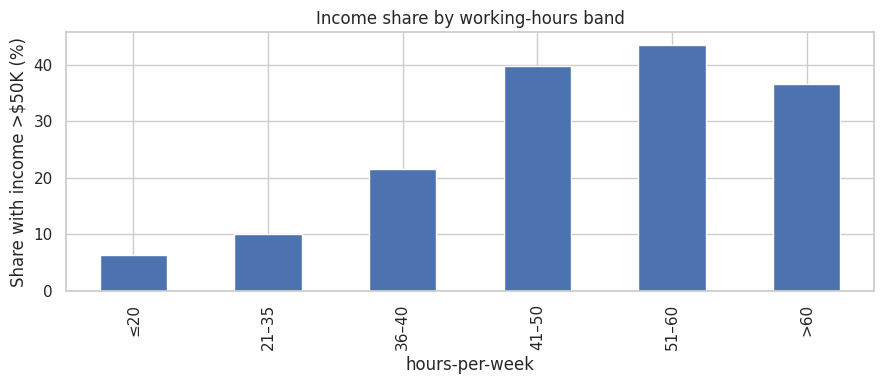

In [27]:
hour_bins=pd.cut(df['hours-per-week'],[0,20,35,40,50,60,np.inf],labels=['≤20','21–35','36–40','41–50','51–60','>60'])
hours_table=pd.crosstab(hour_bins,df['income'],normalize='index').mul(100).round(2)
display(hours_table)
hours_table['>50K'].plot(kind='bar',figsize=(9,4),ylabel='Share with income >$50K (%)',title='Income share by working-hours band')
plt.tight_layout();plt.show()

## 3. Descriptive analysis — categorical attributes

We examine individual census attributes and generate tables and figures directly from the provided data. Subgroup percentages are associations in a historical sample, not evidence of causes.

### 3.1 Work class

We inspect the frequency distribution, group sizes and observed income mix for `workclass`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [28]:
counts=df['workclass'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 7


,records
workclass,
Private,33307
Self-emp-not-inc,3796
Local-gov,3100
State-gov,1946
Self-emp-inc,1646
Federal-gov,1406
Without-pay,21


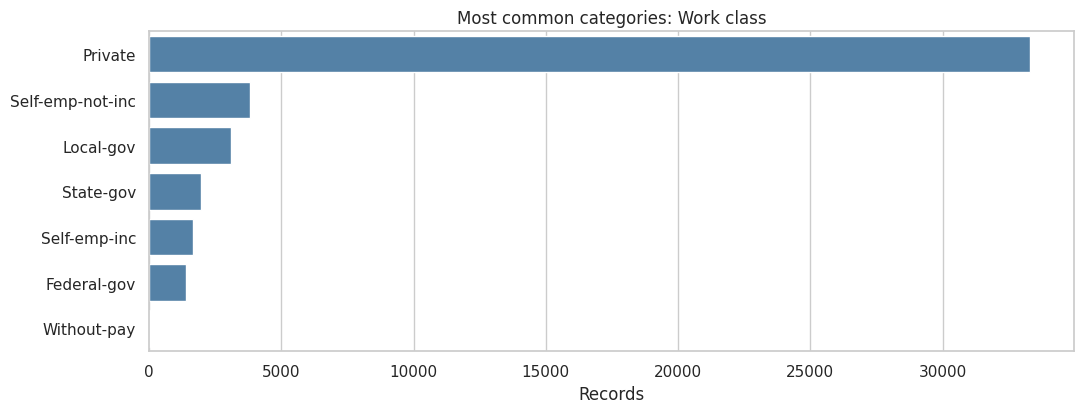

In [29]:
top=df['workclass'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['workclass'].isin(top)],y='workclass',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Work class',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [30]:
summary=df.groupby('workclass',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
workclass,,
Private,33307,21.77
Self-emp-not-inc,3796,27.90
Local-gov,3100,29.52
State-gov,1946,26.72
Self-emp-inc,1646,55.41
Federal-gov,1406,39.05
Without-pay,21,9.52


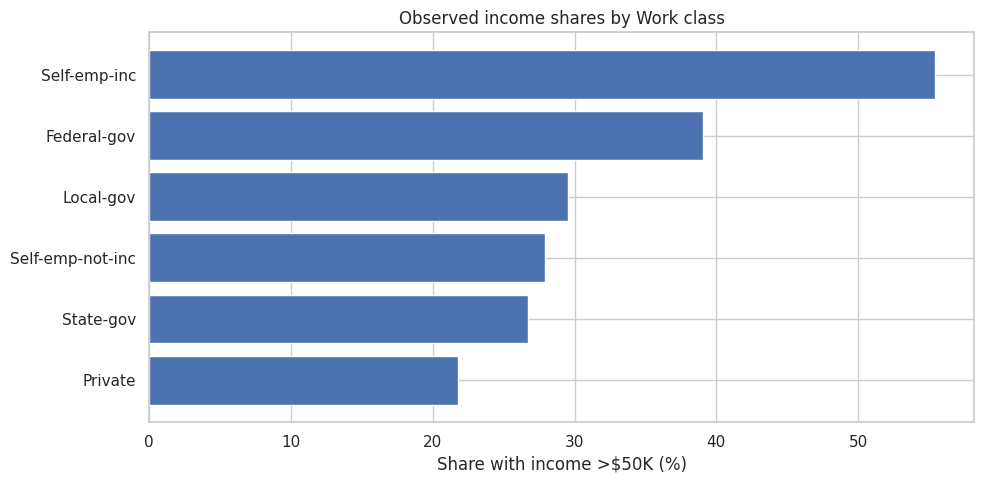

In [31]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Work class')
plt.tight_layout();plt.show()

The `workclass` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.2 Education level

We inspect the frequency distribution, group sizes and observed income mix for `education_level`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [32]:
counts=df['education_level'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 16


,records
education_level,
HS-grad,14783
Some-college,9899
Bachelors,7570
Masters,2514
Assoc-voc,1959
11th,1619
Assoc-acdm,1507
10th,1223
7th-8th,823


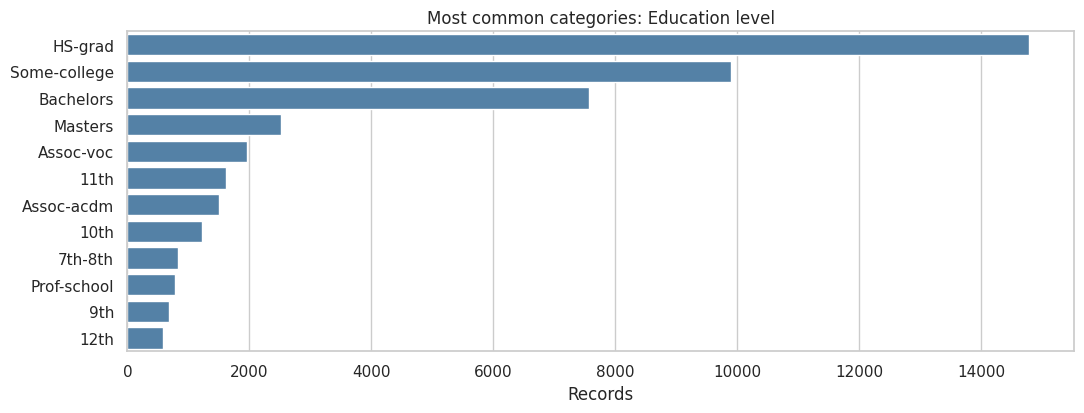

In [33]:
top=df['education_level'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['education_level'].isin(top)],y='education_level',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Education level',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [34]:
summary=df.groupby('education_level',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
education_level,,
HS-grad,14783,16.34
Some-college,9899,20.10
Bachelors,7570,41.98
Masters,2514,55.41
Assoc-voc,1959,25.73
11th,1619,5.50
Assoc-acdm,1507,26.41
10th,1223,6.70
7th-8th,823,6.68


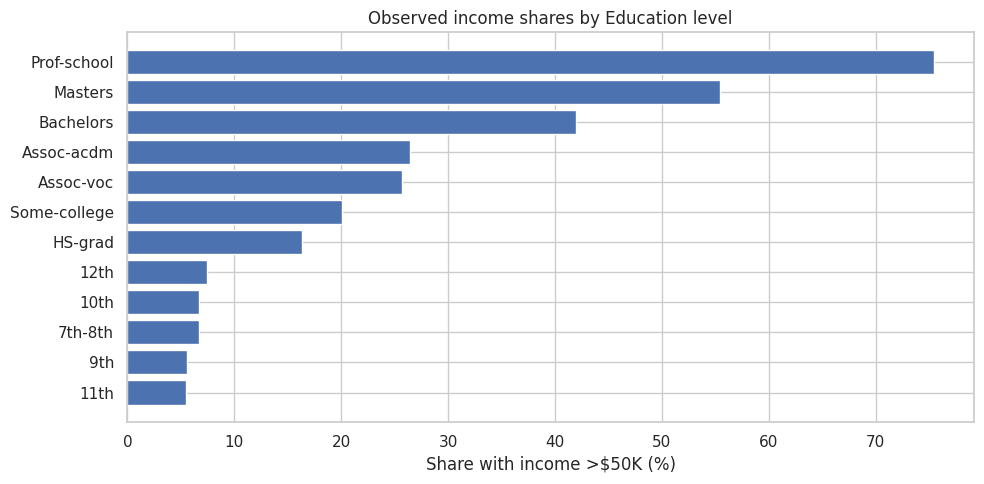

In [35]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Education level')
plt.tight_layout();plt.show()

The `education_level` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.3 Marital status

We inspect the frequency distribution, group sizes and observed income mix for `marital-status`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [36]:
counts=df['marital-status'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 7


,records
marital-status,
Married-civ-spouse,21055
Never-married,14598
Divorced,6297
Separated,1411
Widowed,1277
Married-spouse-absent,552
Married-AF-spouse,32


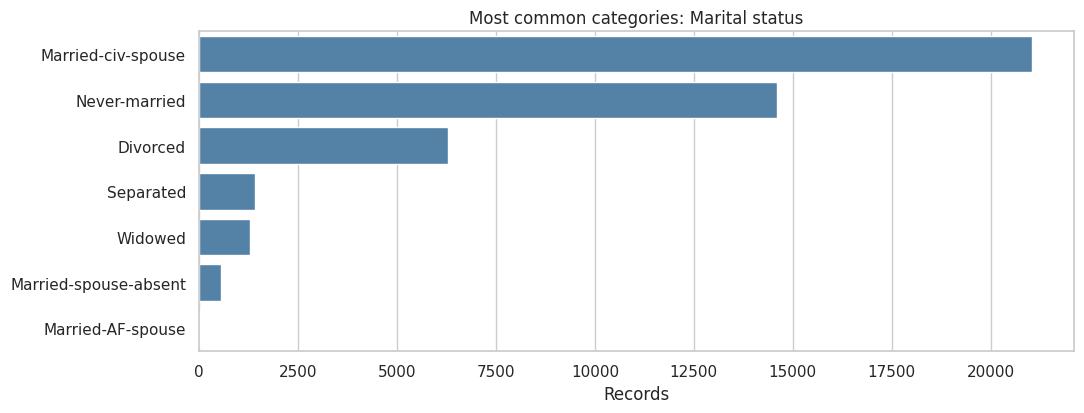

In [37]:
top=df['marital-status'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['marital-status'].isin(top)],y='marital-status',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Marital status',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [38]:
summary=df.groupby('marital-status',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
marital-status,,
Married-civ-spouse,21055,45.42
Never-married,14598,4.80
Divorced,6297,10.40
Separated,1411,7.02
Widowed,1277,9.48
Married-spouse-absent,552,9.78
Married-AF-spouse,32,43.75


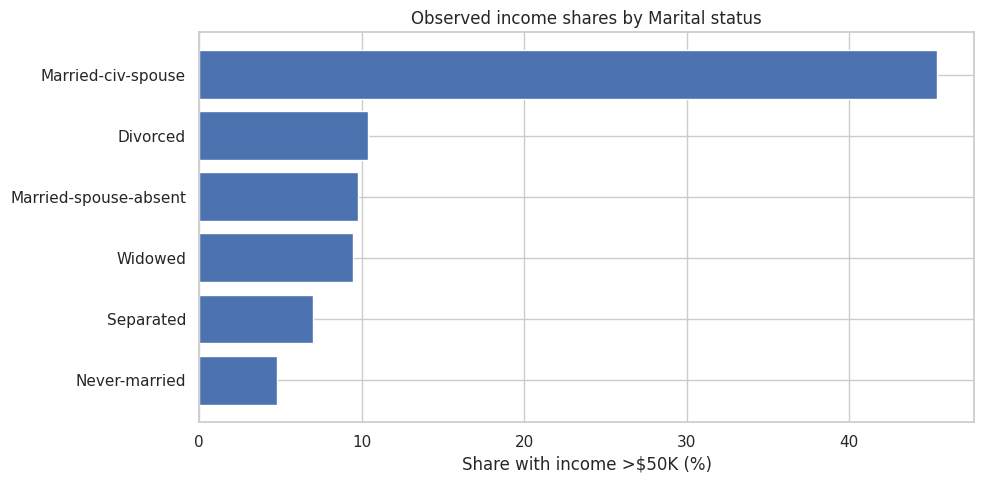

In [39]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Marital status')
plt.tight_layout();plt.show()

The `marital-status` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.4 Occupation

We inspect the frequency distribution, group sizes and observed income mix for `occupation`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [40]:
counts=df['occupation'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 14


,records
occupation,
Craft-repair,6020
Prof-specialty,6008
Exec-managerial,5984
Adm-clerical,5540
Sales,5408
Other-service,4808
Machine-op-inspct,2970
Transport-moving,2316
Handlers-cleaners,2046


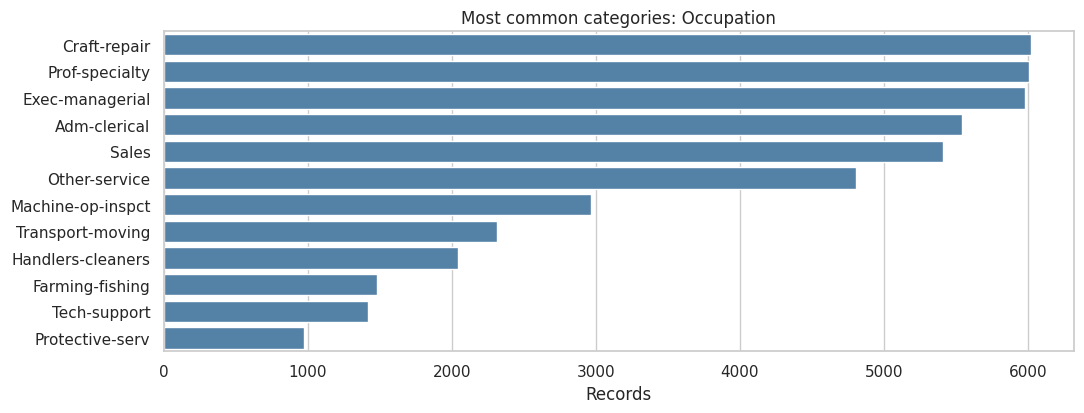

In [41]:
top=df['occupation'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['occupation'].isin(top)],y='occupation',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Occupation',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [42]:
summary=df.groupby('occupation',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
occupation,,
Craft-repair,6020,22.51
Prof-specialty,6008,45.01
Exec-managerial,5984,47.91
Adm-clerical,5540,13.65
Sales,5408,26.90
Other-service,4808,4.08
Machine-op-inspct,2970,12.29
Transport-moving,2316,20.64
Handlers-cleaners,2046,6.60


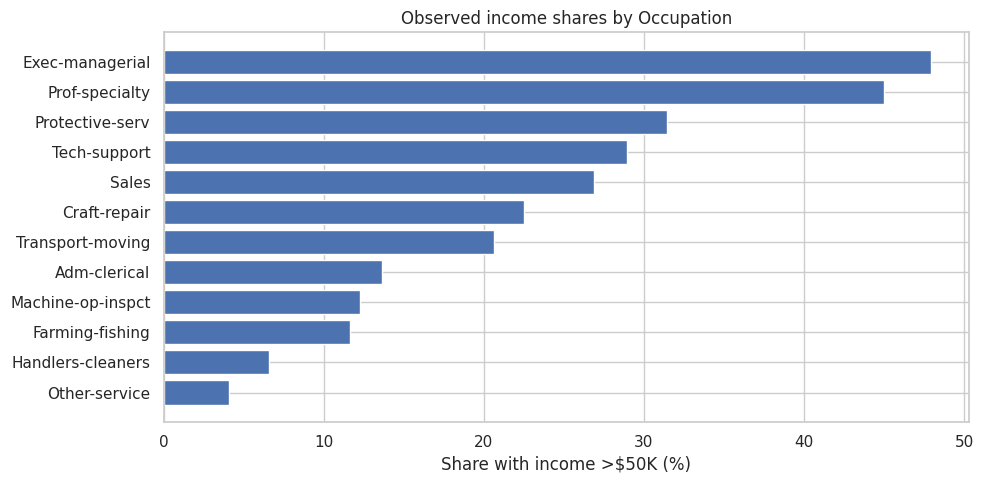

In [43]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Occupation')
plt.tight_layout();plt.show()

The `occupation` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.5 Household relationship

We inspect the frequency distribution, group sizes and observed income mix for `relationship`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [44]:
counts=df['relationship'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 6


,records
relationship,
Husband,18666
Not-in-family,11702
Own-child,6626
Unmarried,4788
Wife,2091
Other-relative,1349


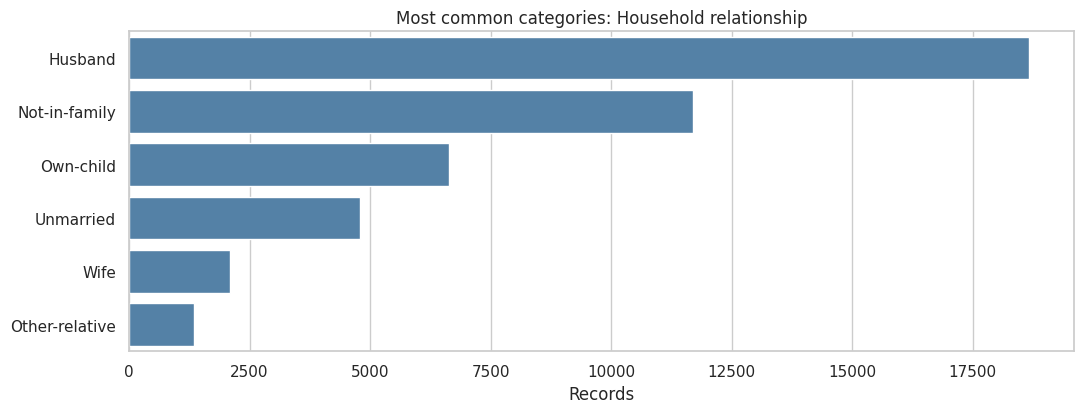

In [45]:
top=df['relationship'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['relationship'].isin(top)],y='relationship',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Household relationship',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [46]:
summary=df.groupby('relationship',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
relationship,,
Husband,18666,45.57
Not-in-family,11702,10.49
Own-child,6626,1.58
Unmarried,4788,6.31
Wife,2091,48.59
Other-relative,1349,3.71


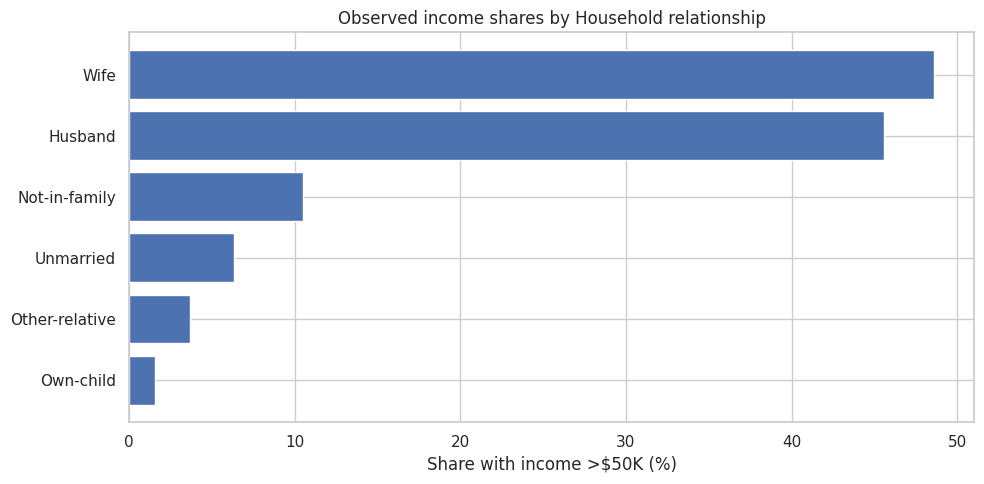

In [47]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Household relationship')
plt.tight_layout();plt.show()

The `relationship` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.6 Sex

We inspect the frequency distribution, group sizes and observed income mix for `sex`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [48]:
counts=df['sex'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 2


,records
sex,
Male,30527
Female,14695


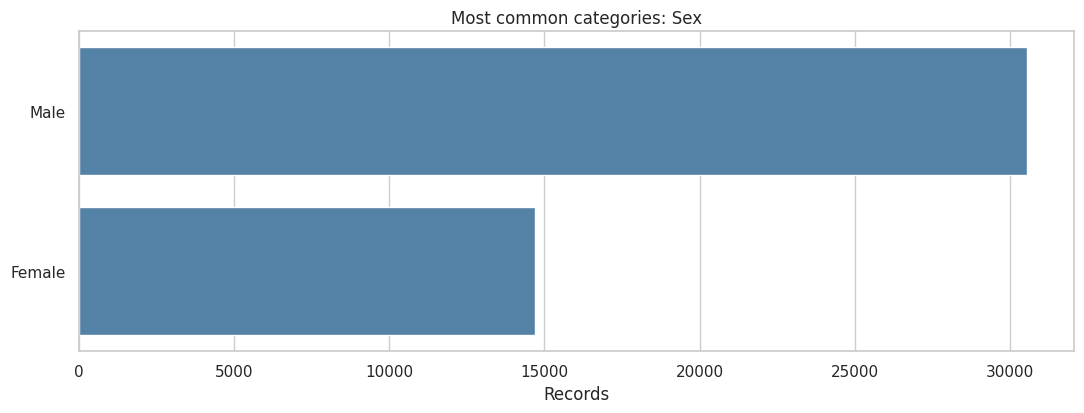

In [49]:
top=df['sex'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['sex'].isin(top)],y='sex',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Sex',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [50]:
summary=df.groupby('sex',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
sex,,
Male,30527,31.25
Female,14695,11.36


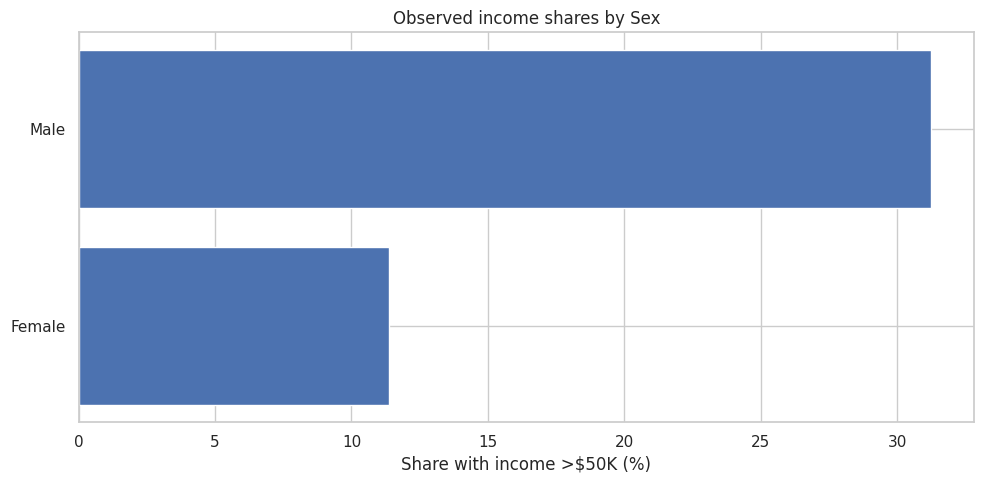

In [51]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Sex')
plt.tight_layout();plt.show()

The `sex` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.7 Race

We inspect the frequency distribution, group sizes and observed income mix for `race`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [52]:
counts=df['race'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 5


,records
race,
White,38903
Black,4228
Asian-Pac-Islander,1303
Amer-Indian-Eskimo,435
Other,353


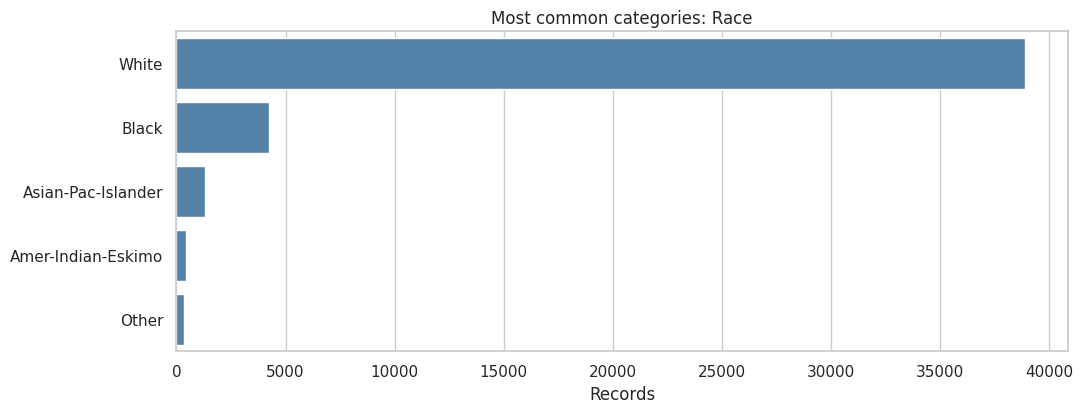

In [53]:
top=df['race'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['race'].isin(top)],y='race',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Race',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [54]:
summary=df.groupby('race',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
race,,
White,38903,26.24
Black,4228,12.63
Asian-Pac-Islander,1303,28.32
Amer-Indian-Eskimo,435,12.18
Other,353,12.75


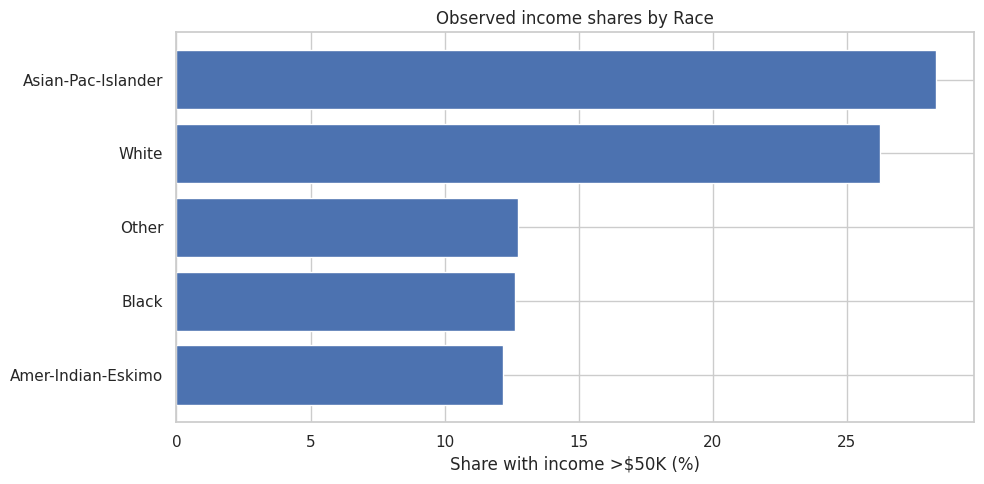

In [55]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Race')
plt.tight_layout();plt.show()

The `race` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.8 Country of origin

We inspect the frequency distribution, group sizes and observed income mix for `native-country`. Comparisons involving demographic characteristics are descriptive and should not be used to justify discriminatory decisions.

In [56]:
counts=df['native-country'].value_counts(dropna=False)
print('Distinct categories:',len(counts))
display(counts.to_frame('records').head(15))

Distinct categories: 41


,records
native-country,
United-States,41292
Mexico,903
Philippines,283
Germany,193
Puerto-Rico,175
Canada,163
El-Salvador,147
India,147
Cuba,133


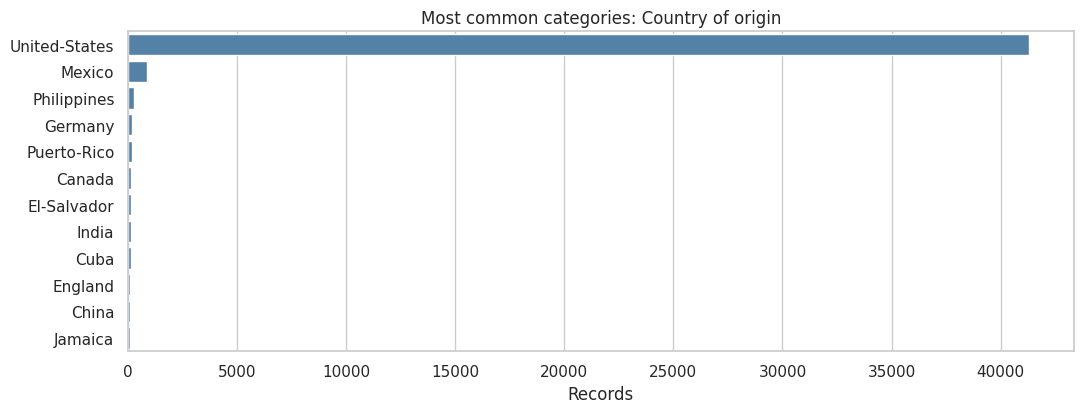

In [57]:
top=df['native-country'].value_counts().head(12).index
fig,ax=plt.subplots(figsize=(11,4.3))
sns.countplot(data=df.loc[df['native-country'].isin(top)],y='native-country',order=top,ax=ax,color='steelblue')
ax.set(title='Most common categories: Country of origin',xlabel='Records',ylabel='')
plt.tight_layout();plt.show()

In [58]:
summary=df.groupby('native-country',observed=True).agg(records=('income','size'),
    above_50k_share=('income',lambda x:(x=='>50K').mean()*100)).sort_values('records',ascending=False)
display(summary.head(15).round(2))

,records,above_50k_share
native-country,,
United-States,41292,25.30
Mexico,903,5.20
Philippines,283,29.68
Germany,193,30.05
Puerto-Rico,175,11.43
Canada,163,36.81
El-Salvador,147,7.48
India,147,42.18
Cuba,133,25.56


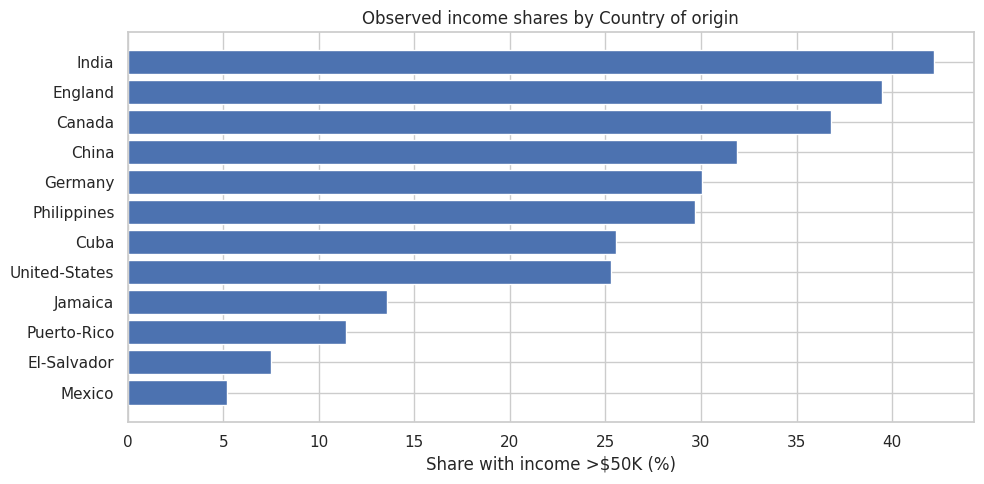

In [59]:
summary_plot=summary.loc[summary.records>=max(50,int(len(df)*.001))].head(12).sort_values('above_50k_share')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(summary_plot.index,summary_plot['above_50k_share'])
ax.set(xlabel='Share with income >$50K (%)',title='Observed income shares by Country of origin')
plt.tight_layout();plt.show()

The `native-country` comparison describes **historical dataset composition**. Small groups can have unstable rates, and demographic effects are entangled with education, occupation, working patterns and unequal access to opportunity.

### 3.9 Education and occupation cross-tabulation

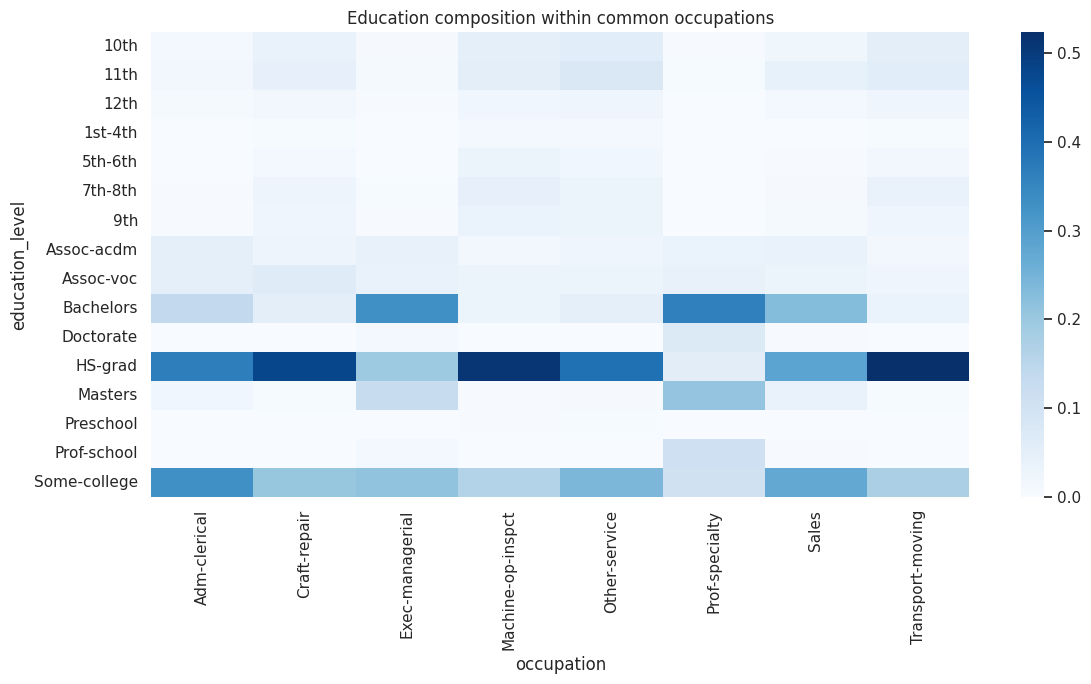

In [60]:
top_occ=df['occupation'].value_counts().head(8).index
edu_occ=pd.crosstab(df.loc[df['occupation'].isin(top_occ),'education_level'],
                    df.loc[df['occupation'].isin(top_occ),'occupation'],normalize='columns')
fig,ax=plt.subplots(figsize=(12,7))
sns.heatmap(edu_occ,cmap='Blues',ax=ax)
ax.set_title('Education composition within common occupations')
plt.tight_layout();plt.show()

### 3.10 Joint effects of work class and hours

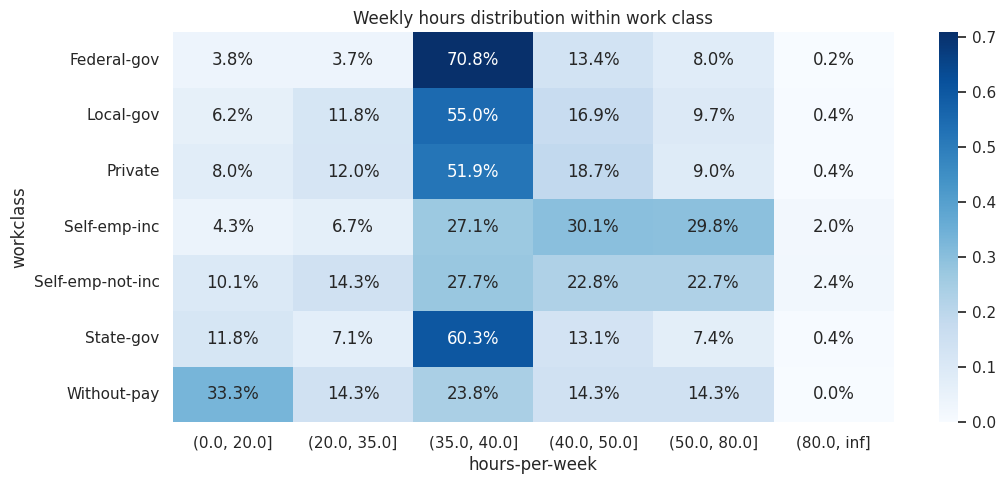

In [61]:
work_hour=pd.crosstab(df['workclass'],pd.cut(df['hours-per-week'],[0,20,35,40,50,80,np.inf]),normalize='index')
fig,ax=plt.subplots(figsize=(11,5))
sns.heatmap(work_hour,annot=True,fmt='.1%',cmap='Blues',ax=ax)
ax.set_title('Weekly hours distribution within work class')
plt.tight_layout();plt.show()

### 3.11 Descriptive subgroup sample sizes

In [62]:
for col in ['sex','race']:
    display(df.groupby(col).agg(records=('income','size'),above_50k=('income',lambda s: (s=='>50K').sum()),
        rate_percent=('income',lambda s:round((s=='>50K').mean()*100,2))))

,records,above_50k,rate_percent
sex,,,
Female,14695,1669,11.36
Male,30527,9539,31.25


,records,above_50k,rate_percent
race,,,
Amer-Indian-Eskimo,435,53,12.18
Asian-Pac-Islander,1303,369,28.32
Black,4228,534,12.63
Other,353,45,12.75
White,38903,10207,26.24


## 4. Feature preparation and holdout design

We now move from description to classification. Preprocessing is fitted on training data only, and every model is evaluated against one consistent group-aware holdout. `race` and `sex` are excluded as inputs, while retained for the group-level audit.

In [63]:
y=df['income'].map({'<=50K':0,'>50K':1}).astype(int)
sensitive=df[['race','sex']].copy()
# Avoid duplicating the same education information in two model features and exclude protected attributes.
X=df.drop(columns=['income','race','sex','education_level']).copy()
num_features=X.select_dtypes(include=np.number).columns.tolist()
cat_features=X.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric input features:',num_features)
print('Categorical input features:',cat_features)
print('Excluded from predictors: income, race, sex, education_level')
print('Input matrix:',X.shape)

Numeric input features: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical input features: ['workclass', 'marital-status', 'occupation', 'relationship', 'native-country']
Excluded from predictors: income, race, sex, education_level
Input matrix: (45222, 10)


**Data leakage precaution:** grouping identical predictor rows avoids placing identical feature patterns in both the training and test sets. The split is not stratified by class, so we report observed class distributions after splitting. This does not prevent every possible form of leakage or demographic bias.

In [64]:
groups=pd.util.hash_pandas_object(X,index=False).to_numpy()
splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
tr_idx,te_idx=next(splitter.split(X,y,groups=groups))
X_train,X_test=X.iloc[tr_idx].copy(),X.iloc[te_idx].copy()
y_train,y_test=y.iloc[tr_idx].copy(),y.iloc[te_idx].copy()
train_groups=groups[tr_idx]
print('Train:',X_train.shape,'Test:',X_test.shape)
print('Input-group overlap:',len(set(train_groups).intersection(set(groups[te_idx]))))
display(pd.DataFrame({'dataset':['train','test'],
    'rows':[len(y_train),len(y_test)],'positive_rate':[y_train.mean(),y_test.mean()]}))
assert not set(train_groups).intersection(set(groups[te_idx]))

Train: (36061, 10) Test: (9161, 10)
Input-group overlap: 0


,dataset,rows,positive_rate
0,train,36061,0.249411
1,test,9161,0.241677


### 4.1 Leakage-safe preprocessing pipeline

In [65]:
numeric_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
categorical_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
preprocessor=ColumnTransformer([('numeric',numeric_pipeline,num_features),
    ('categorical',categorical_pipeline,cat_features)],sparse_threshold=0)
print('All preprocessing is learned from training records only.')

All preprocessing is learned from training records only.


The use of a `Pipeline` prevents the encoder, imputer and scaler from learning parameters from the held-out test set. The common data split makes the classifier comparisons directly comparable. We also include a majority-class baseline to contextualise accuracy.

## 5. Supervised machine-learning models

We evaluate Logistic Regression, Random Forest, Gaussian Naive Bayes, a Neural Network (MLP) and Gradient Boosting with the same held-out data and metrics.

In [66]:
model_specs={
    'Majority-class baseline':DummyClassifier(strategy='most_frequent'),
    'Logistic Regression':LogisticRegression(max_iter=1400,random_state=SEED),
    'Random Forest':RandomForestClassifier(n_estimators=120,min_samples_leaf=3,n_jobs=-1,random_state=SEED),
    'Gaussian Naive Bayes':GaussianNB(),
    'Neural Network (MLP)':MLPClassifier(hidden_layer_sizes=(32,),max_iter=90,
        early_stopping=True,n_iter_no_change=10,random_state=SEED),
    'Gradient Boosting':HistGradientBoostingClassifier(max_iter=130,max_leaf_nodes=17,
        learning_rate=.07,random_state=SEED)
}
fitted={};predictions={};probabilities={};results=[]
def model_metrics(name,y_true,y_pred,y_prob):
    return dict(Model=name,Accuracy=accuracy_score(y_true,y_pred),
      Balanced_Accuracy=balanced_accuracy_score(y_true,y_pred),
      Precision=precision_score(y_true,y_pred,zero_division=0),
      Recall=recall_score(y_true,y_pred,zero_division=0),
      F1=f1_score(y_true,y_pred,zero_division=0),
      ROC_AUC=roc_auc_score(y_true,y_prob),
      PR_AUC=average_precision_score(y_true,y_prob))
print('Planned models:',', '.join(model_specs))

Planned models: Majority-class baseline, Logistic Regression, Random Forest, Gaussian Naive Bayes, Neural Network (MLP), Gradient Boosting


### 5.1 Majority-class baseline

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [67]:
name='Majority-class baseline'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Majority-class baseline,0.7583,0.5,0.0,0.0,0.0,0.5,0.2417


In [68]:
name='Majority-class baseline'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.76      1.00      0.86      6947
       >$50K       0.00      0.00      0.00      2214

    accuracy                           0.76      9161
   macro avg       0.38      0.50      0.43      9161
weighted avg       0.58      0.76      0.65      9161



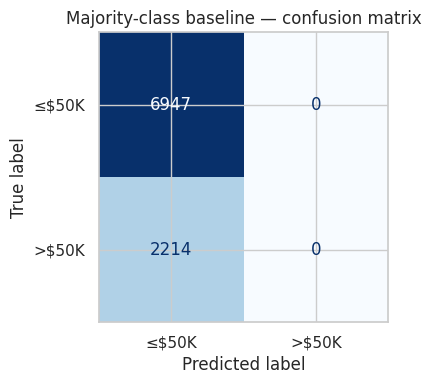

In [69]:
name='Majority-class baseline'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Majority-class baseline — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

### 5.2 Logistic Regression

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [70]:
name='Logistic Regression'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.8502,0.7626,0.736,0.593,0.6568,0.9084,0.7681


In [71]:
name='Logistic Regression'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.88      0.93      0.90      6947
       >$50K       0.74      0.59      0.66      2214

    accuracy                           0.85      9161
   macro avg       0.81      0.76      0.78      9161
weighted avg       0.84      0.85      0.84      9161



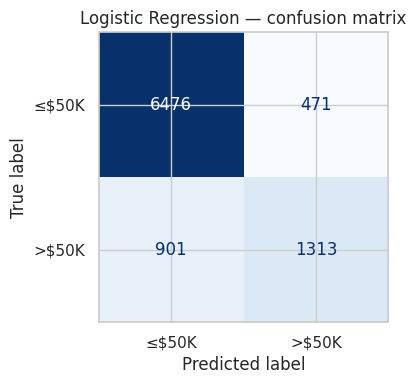

In [72]:
name='Logistic Regression'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Logistic Regression — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

### 5.3 Random Forest

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [73]:
name='Random Forest'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.862,0.7736,0.7765,0.6025,0.6785,0.9209,0.8073


In [74]:
name='Random Forest'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.88      0.94      0.91      6947
       >$50K       0.78      0.60      0.68      2214

    accuracy                           0.86      9161
   macro avg       0.83      0.77      0.80      9161
weighted avg       0.86      0.86      0.86      9161



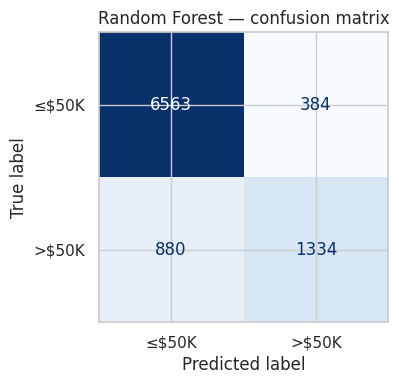

In [75]:
name='Random Forest'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Random Forest — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

### 5.4 Gaussian Naive Bayes

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [76]:
name='Gaussian Naive Bayes'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Gaussian Naive Bayes,0.6267,0.7348,0.388,0.944,0.55,0.8632,0.6373


In [77]:
name='Gaussian Naive Bayes'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.97      0.53      0.68      6947
       >$50K       0.39      0.94      0.55      2214

    accuracy                           0.63      9161
   macro avg       0.68      0.73      0.62      9161
weighted avg       0.83      0.63      0.65      9161



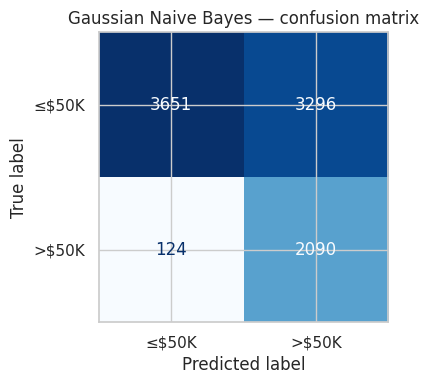

In [78]:
name='Gaussian Naive Bayes'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Gaussian Naive Bayes — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

### 5.5 Neural Network (MLP)

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [79]:
name='Neural Network (MLP)'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Neural Network (MLP),0.8536,0.7678,0.7437,0.6016,0.6652,0.9134,0.7792


In [80]:
name='Neural Network (MLP)'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.88      0.93      0.91      6947
       >$50K       0.74      0.60      0.67      2214

    accuracy                           0.85      9161
   macro avg       0.81      0.77      0.79      9161
weighted avg       0.85      0.85      0.85      9161



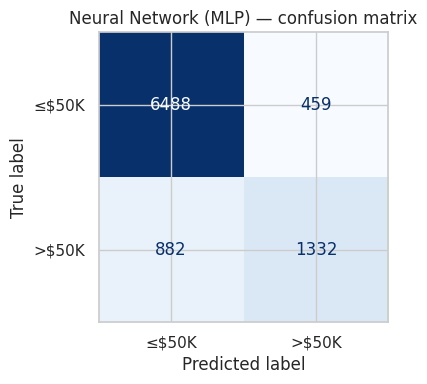

In [81]:
name='Neural Network (MLP)'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Neural Network (MLP) — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

### 5.6 Gradient Boosting

This classifier is trained on the same training records and evaluated on the same held-out test records. The standard 0.50 decision threshold is used here; thresholds are examined separately later.

In [82]:
name='Gradient Boosting'
pipe=Pipeline([('preprocess',clone(preprocessor)),('model',clone(model_specs[name]))])
pipe.fit(X_train,y_train)
fitted[name]=pipe
predictions[name]=pipe.predict(X_test)
probabilities[name]=pipe.predict_proba(X_test)[:,1]
results.append(model_metrics(name,y_test,predictions[name],probabilities[name]))
display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Gradient Boosting,0.8713,0.7944,0.7839,0.6454,0.708,0.9298,0.8291


In [83]:
name='Gradient Boosting'
print(classification_report(y_test,predictions[name],target_names=['≤$50K','>$50K'],zero_division=0))

              precision    recall  f1-score   support

       ≤$50K       0.89      0.94      0.92      6947
       >$50K       0.78      0.65      0.71      2214

    accuracy                           0.87      9161
   macro avg       0.84      0.79      0.81      9161
weighted avg       0.87      0.87      0.87      9161



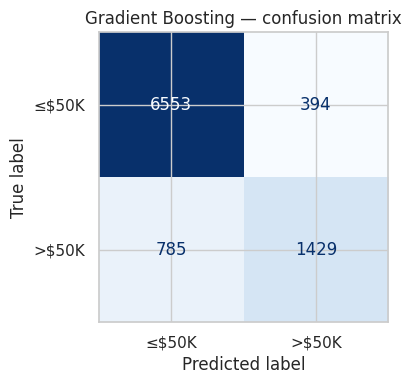

In [84]:
name='Gradient Boosting'
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=['≤$50K','>$50K'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Gradient Boosting — confusion matrix')
plt.tight_layout();plt.show()

Consider false negatives (people in the higher-income class classified as lower income) and false positives together. High accuracy does not guarantee good minority-class recall.

## 6. Comparative model evaluation

We compare model quality using consistent metrics, confusion matrices and discrimination curves. ROC-AUC and PR-AUC are threshold-independent rankings, while F1 and recall depend on the 0.50 threshold.

In [85]:
scoreboard=pd.DataFrame(results).sort_values(['F1','ROC_AUC'],ascending=False).reset_index(drop=True)
display(scoreboard.style.format({x:'{:.3f}' for x in scoreboard.select_dtypes('number').columns}))
best_name=str(scoreboard.iloc[0]['Model'])
print('Best model by held-out F1:',best_name)

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Gradient Boosting,0.871,0.794,0.784,0.645,0.708,0.930,0.829
1,Random Forest,0.862,0.774,0.776,0.603,0.679,0.921,0.807
2,Neural Network (MLP),0.854,0.768,0.744,0.602,0.665,0.913,0.779
3,Logistic Regression,0.850,0.763,0.736,0.593,0.657,0.908,0.768
4,Gaussian Naive Bayes,0.627,0.735,0.388,0.944,0.550,0.863,0.637
5,Majority-class baseline,0.758,0.500,0.000,0.000,0.000,0.500,0.242


Best model by held-out F1: Gradient Boosting


### 6.1 Accuracy and balanced accuracy

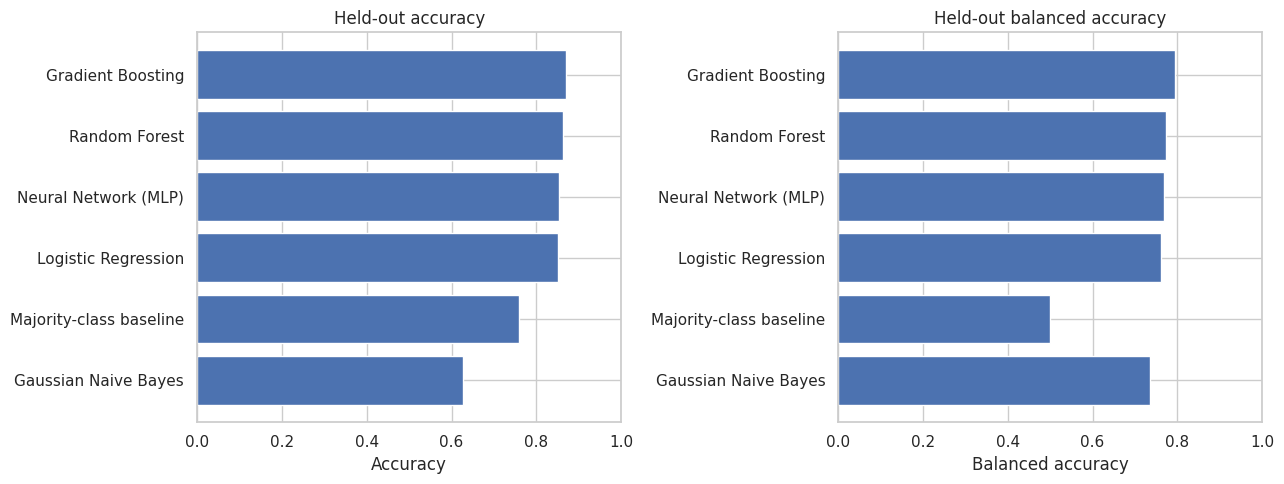

In [86]:
compare=scoreboard.sort_values('Accuracy')
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].barh(compare.Model,compare.Accuracy)
axes[0].set(xlim=(0,1),xlabel='Accuracy',title='Held-out accuracy')
axes[1].barh(compare.Model,compare.Balanced_Accuracy)
axes[1].set(xlim=(0,1),xlabel='Balanced accuracy',title='Held-out balanced accuracy')
plt.tight_layout();plt.show()

### 6.2 Precision, recall and F1

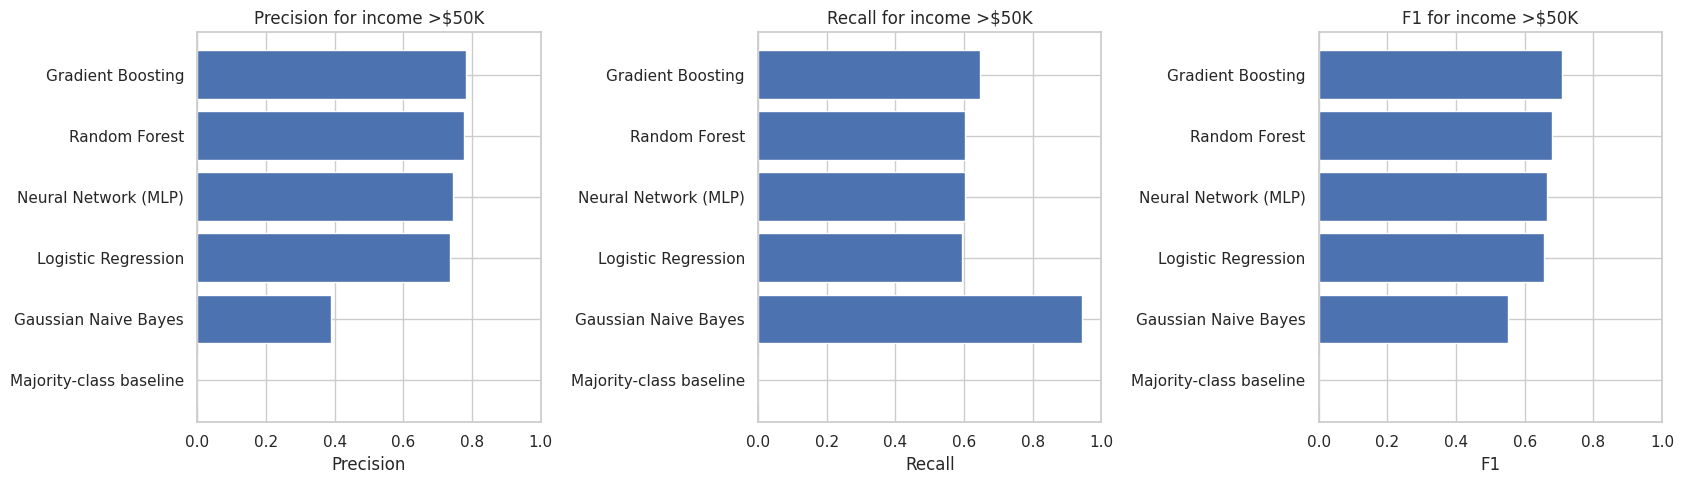

In [87]:
compare=scoreboard.sort_values('F1')
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,metric in zip(axes,['Precision','Recall','F1']):
    ax.barh(compare.Model,compare[metric]);ax.set(xlim=(0,1),xlabel=metric,title=metric+' for income >$50K')
plt.tight_layout();plt.show()

### 6.3 ROC curves

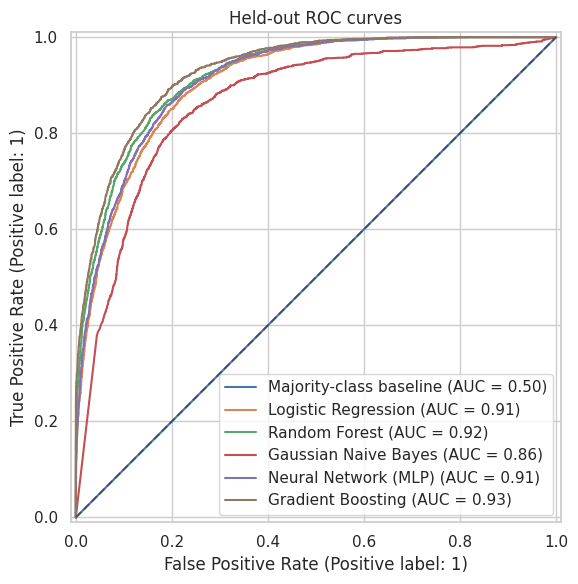

In [88]:
fig,ax=plt.subplots(figsize=(8,6))
for name in model_specs:
    RocCurveDisplay.from_predictions(y_test,probabilities[name],name=name,ax=ax)
ax.plot([0,1],[0,1],'k--',alpha=.4)
ax.set_title('Held-out ROC curves')
plt.tight_layout();plt.show()

### 6.4 Precision–recall curves

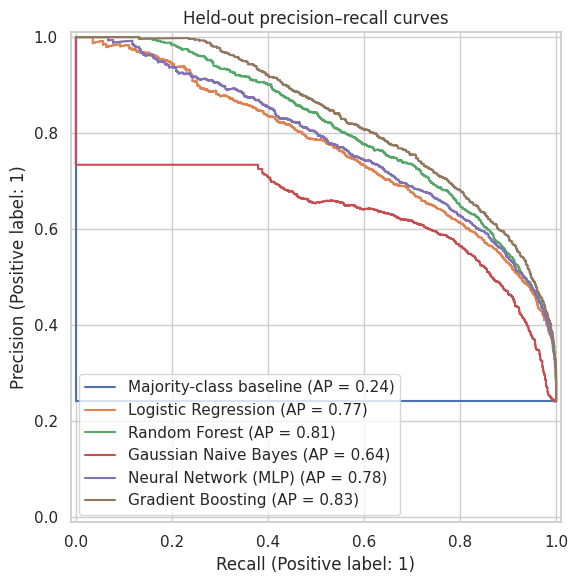

In [89]:
fig,ax=plt.subplots(figsize=(8,6))
for name in model_specs:
    PrecisionRecallDisplay.from_predictions(y_test,probabilities[name],name=name,ax=ax)
ax.set_title('Held-out precision–recall curves')
plt.tight_layout();plt.show()

### 6.5 Model-selection caveat

Choosing the winning model by its test-set F1 is useful for describing the comparison, but it introduces selection bias if the test set is used repeatedly to choose new models or tune thresholds. Future work should use nested validation or a separate, untouched final evaluation set. Here, the principal tuned experiment uses **training-only** cross-validation.

## 7. Unsupervised exploration: K-Means clustering

We also explore clustering. Unlike supervised income classification, clustering identifies similarities in features without using income labels to form clusters. We examine whether crude numerical clusters line up with the labels, without treating clustering as a replacement classifier.

In [90]:
cluster_features=['age','education-num','hours-per-week','capital-gain','capital-loss']
cluster_sample=df.sample(n=min(4500,len(df)),random_state=SEED).copy()
cluster_scaled=StandardScaler().fit_transform(np.log1p(cluster_sample[cluster_features].clip(lower=0)))
print('Cluster sample:',cluster_scaled.shape)

Cluster sample: (4500, 5)


### 7.1 K choice and silhouette

In [91]:
cluster_summary=[]
for k in (2,3,4,5):
    km=KMeans(n_clusters=k,random_state=SEED,n_init=5)
    lab=km.fit_predict(cluster_scaled)
    sil=silhouette_score(cluster_scaled,lab,sample_size=min(1200,len(lab)),random_state=SEED)
    cluster_summary.append({'k':k,'inertia':km.inertia_,'silhouette':sil})
display(pd.DataFrame(cluster_summary).round(3))

,k,inertia,silhouette
0,2,17887.285,0.472
1,3,13338.998,0.525
2,4,10501.249,0.439
3,5,8379.539,0.352


### 7.2 Cluster profile

In [92]:
k=3
km=KMeans(n_clusters=k,random_state=SEED,n_init=10)
cluster_sample['cluster']=km.fit_predict(cluster_scaled)
display(cluster_sample.groupby('cluster')[cluster_features].median())
display(pd.crosstab(cluster_sample.cluster,cluster_sample.income,normalize='index').round(3))

,age,education-num,hours-per-week,capital-gain,capital-loss
cluster,,,,,
0,36.0,10.0,40.0,0.0,0.0
1,43.0,10.0,40.0,0.0,1902.0
2,43.0,11.0,40.0,7298.0,0.0


income,<=50K,>50K
cluster,,
0,0.802,0.198
1,0.440,0.560
2,0.345,0.655


### 7.3 Principal component visualisation

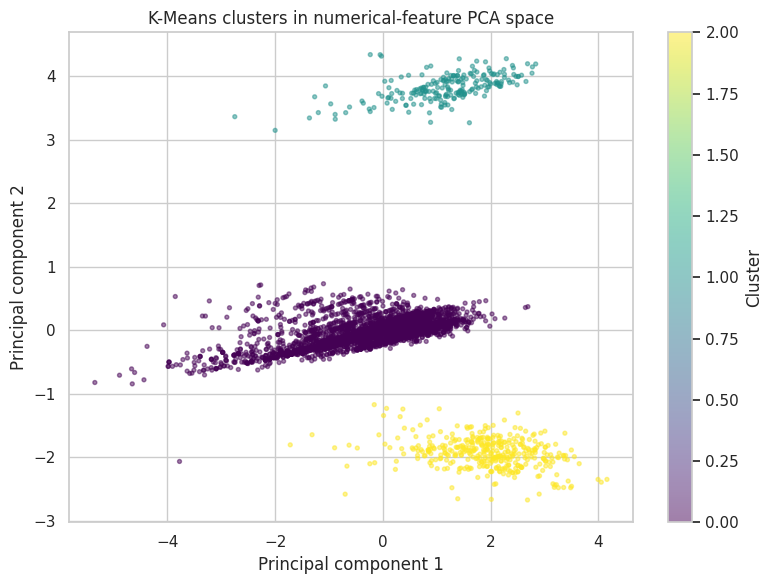

In [93]:
pca=PCA(n_components=2,random_state=SEED)
coords=pca.fit_transform(cluster_scaled)
fig,ax=plt.subplots(figsize=(8,6))
scatter=ax.scatter(coords[:,0],coords[:,1],c=cluster_sample.cluster,cmap='viridis',s=8,alpha=.5)
ax.set(xlabel='Principal component 1',ylabel='Principal component 2',title='K-Means clusters in numerical-feature PCA space')
fig.colorbar(scatter,ax=ax,label='Cluster')
plt.tight_layout();plt.show()

K-Means group membership is an **unsupervised exploratory result** and should not be reported as a predictive accuracy score. Its interpretation is limited by the numeric-only feature subset and the arbitrary choice of cluster count.

## 8. Training-only optimisation

Rather than tuning on the held-out test labels, we use group-aware cross-validation on a fixed 12,000-record subset of the training set to compare a limited set of Logistic Regression settings. The chosen model is then refit on the full training set. This demonstrates hyperparameter tuning without leaking test information into the chosen hyperparameters.

### 8.1 Group-based cross-validation

In [94]:
cv=GroupKFold(n_splits=3)
# Tune on a fixed 12,000-row training-only subset to make the example practical to rerun.
search_idx=np.random.default_rng(SEED).choice(len(X_train),size=min(12000,len(X_train)),replace=False)
X_cv=X_train.iloc[search_idx];y_cv=y_train.iloc[search_idx];groups_cv=train_groups[search_idx]
search_pipeline=Pipeline([('preprocess',clone(preprocessor)),('model',LogisticRegression(
    solver='liblinear',max_iter=400,random_state=SEED))])
search_grid={'model__C':[0.1,1.,10.], 'model__class_weight':[None,'balanced']}
search=GridSearchCV(search_pipeline,search_grid,cv=cv,scoring='f1',n_jobs=1,refit=True)
search.fit(X_cv,y_cv,groups=groups_cv)
print('Training-only CV subset:',len(X_cv))
print('Best train-CV parameters:',search.best_params_)
print('Mean train-CV F1:',round(search.best_score_,3))

Training-only CV subset: 12000
Best train-CV parameters: {'model__C': 1.0, 'model__class_weight': 'balanced'}
Mean train-CV F1: 0.676


### 8.2 Cross-validation results

In [95]:
cv_table=pd.DataFrame(search.cv_results_)[['param_model__C','param_model__class_weight','mean_test_score','std_test_score','rank_test_score']]
display(cv_table.sort_values('rank_test_score').round(4))

,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
3,1.0,balanced,0.6757,0.0143,1
5,10.0,balanced,0.6757,0.0136,2
1,0.1,balanced,0.6743,0.0123,3
4,10.0,None,0.6610,0.0071,4
2,1.0,None,0.6597,0.0062,5
0,0.1,None,0.6542,0.0063,6


### 8.3 Holdout evaluation of tuned model

In [96]:
tuned_lr=clone(search.best_estimator_).fit(X_train,y_train)
tuned_lr_prob=tuned_lr.predict_proba(X_test)[:,1]
tuned_lr_pred=tuned_lr.predict(X_test)
tuned_lr_metrics=model_metrics('Tuned Logistic Regression',y_test,tuned_lr_pred,tuned_lr_prob)
display(pd.DataFrame([tuned_lr_metrics]).round(4))
print(classification_report(y_test,tuned_lr_pred,zero_division=0))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,0.8146,0.8249,0.58,0.8446,0.6878,0.9083,0.7662


              precision    recall  f1-score   support

           0       0.94      0.81      0.87      6947
           1       0.58      0.84      0.69      2214

    accuracy                           0.81      9161
   macro avg       0.76      0.82      0.78      9161
weighted avg       0.85      0.81      0.82      9161



### 8.4 Comparing tuned and untuned Logistic Regression

In [97]:
lr_comparison=pd.DataFrame([next(r for r in results if r['Model']=='Logistic Regression'),tuned_lr_metrics])
display(lr_comparison.round(4))

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.8502,0.7626,0.736,0.5930,0.6568,0.9084,0.7681
1,Tuned Logistic Regression,0.8146,0.8249,0.580,0.8446,0.6878,0.9083,0.7662


### 8.5 Decision threshold sensitivity (illustrative only)

,threshold,precision,recall,F1
0,0.2,0.522,0.920,0.666
1,0.3,0.613,0.845,0.710
2,0.4,0.710,0.730,0.720
3,0.5,0.776,0.603,0.679
4,0.6,0.845,0.488,0.619
5,0.7,0.917,0.361,0.518
6,0.8,0.978,0.218,0.357


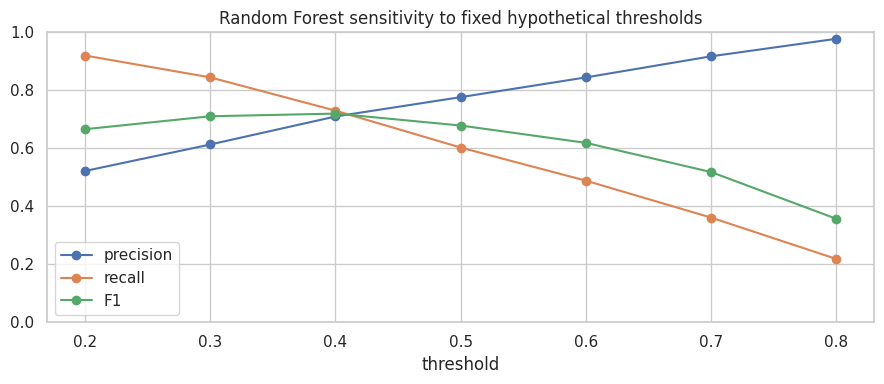

In [98]:
rf_prob=probabilities['Random Forest']
threshold_rows=[]
for t in np.arange(.2,.81,.1):
    yp=(rf_prob>=t).astype(int)
    threshold_rows.append({'threshold':round(t,2),'precision':precision_score(y_test,yp,zero_division=0),
        'recall':recall_score(y_test,yp,zero_division=0),'F1':f1_score(y_test,yp,zero_division=0)})
threshold_table=pd.DataFrame(threshold_rows)
display(threshold_table.round(3))
threshold_table.set_index('threshold')[['precision','recall','F1']].plot(figsize=(9,4),marker='o',title='Random Forest sensitivity to fixed hypothetical thresholds')
plt.ylim(0,1);plt.tight_layout();plt.show()

**Do not pick a threshold using the test-set plot.** The curve is an explanatory sensitivity analysis; any operating threshold must be selected on validation data and then assessed on untouched test data.

## 9. Interpreting classifier behaviour

Feature importance indicates what the fitted model uses for prediction. It does not establish that any variable causes income differences.

### 9.1 Permutation importance — Random Forest

In [99]:
rng=np.random.default_rng(SEED)
index_sample=rng.choice(len(X_test),size=min(1300,len(X_test)),replace=False)
X_imp=X_test.iloc[index_sample];y_imp=y_test.iloc[index_sample]
importance=permutation_importance(fitted['Random Forest'],X_imp,y_imp,
    scoring='f1',n_repeats=3,random_state=SEED,n_jobs=1)
feature_importance=pd.DataFrame({'feature':X_test.columns,'mean_importance':importance.importances_mean,
    'std_importance':importance.importances_std}).sort_values('mean_importance',ascending=False)
display(feature_importance.round(4))

,feature,mean_importance,std_importance
3,marital-status,0.1435,0.0047
6,capital-gain,0.0874,0.0100
5,relationship,0.0726,0.0165
4,occupation,0.0573,0.0230
2,education-num,0.0411,0.0148
0,age,0.0399,0.0126
7,capital-loss,0.0210,0.0011
8,hours-per-week,0.0159,0.0095
1,workclass,0.0086,0.0078
9,native-country,-0.0005,0.0014


### 9.2 Plotting model reliance

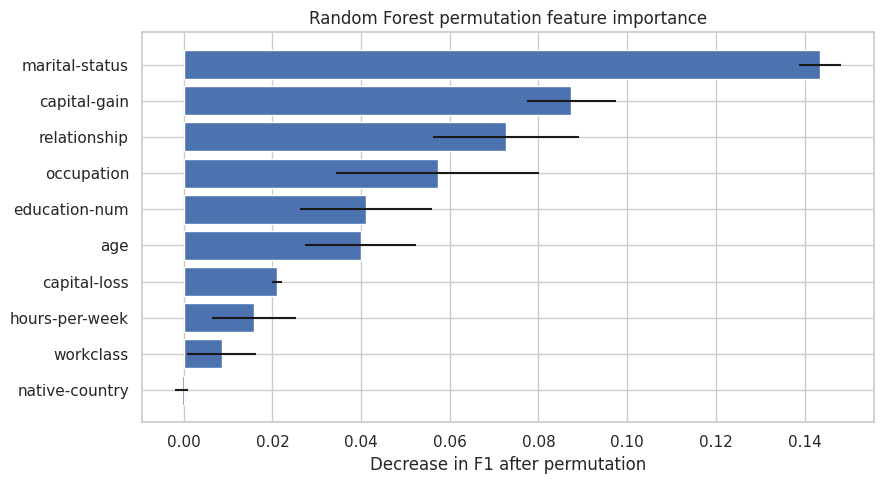

In [100]:
fig,ax=plt.subplots(figsize=(9,5))
plot_importance=feature_importance.sort_values('mean_importance')
ax.barh(plot_importance.feature,plot_importance.mean_importance,xerr=plot_importance.std_importance)
ax.set(xlabel='Decrease in F1 after permutation',title='Random Forest permutation feature importance')
plt.tight_layout();plt.show()

### 9.3 Probability calibration summary

In [101]:
calibration=pd.DataFrame([{'Model':name,'Brier score':brier_score_loss(y_test,proba)} for name,proba in probabilities.items()]).sort_values('Brier score')
display(calibration.round(4))

,Model,Brier score
5,Gradient Boosting,0.0884
2,Random Forest,0.0953
4,Neural Network (MLP),0.0994
1,Logistic Regression,0.1020
0,Majority-class baseline,0.2417
3,Gaussian Naive Bayes,0.3600


Lower Brier scores indicate lower mean squared error of predicted probabilities. Calibration should be separately assessed with reliability diagrams and validation if probabilities will be used for decisions.

## 10. Error and subgroup diagnostics

We explore predictive errors across historical demographic groups **without using race or sex as predictor variables**. Excluding columns is not sufficient to guarantee fairness, because retained features may act as proxies.

In [102]:
best_model_name=scoreboard.loc[0,'Model']
best_pred=predictions[best_model_name]
best_proba=probabilities[best_model_name]
print('Top held-out F1 model:',best_model_name)
print('Confusion matrix (truth in rows):')
display(pd.DataFrame(confusion_matrix(y_test,best_pred),index=['≤50K','>50K'],columns=['Pred ≤50K','Pred >50K']))

Top held-out F1 model: Gradient Boosting
Confusion matrix (truth in rows):


,Pred ≤50K,Pred >50K
≤50K,6553,394
>50K,785,1429


### 10.1 Error audit by sex

In [103]:
audit=sensitive.iloc[te_idx].copy()
audit['actual']=y_test.to_numpy();audit['predicted']=best_pred
def subgroup_audit(frame,feature,min_count=80):
    rows=[]
    for value,sub in frame.groupby(feature):
        if len(sub)<min_count:continue
        rows.append({'group':value,'count':len(sub),'actual_positive_rate':sub.actual.mean(),
            'predicted_positive_rate':sub.predicted.mean(),
            'accuracy':accuracy_score(sub.actual,sub.predicted),
            'recall_positive':recall_score(sub.actual,sub.predicted,zero_division=0),
            'false_positive_rate':((sub.actual.eq(0)&sub.predicted.eq(1)).sum()/max(1,sub.actual.eq(0).sum()))})
    return pd.DataFrame(rows)
display(subgroup_audit(audit,'sex').round(3))

,group,count,actual_positive_rate,predicted_positive_rate,accuracy,recall_positive,false_positive_rate
0,Female,2975,0.107,0.083,0.939,0.601,0.021
1,Male,6186,0.306,0.255,0.839,0.653,0.079


### 10.2 Error audit by race

In [104]:
display(subgroup_audit(audit,'race').round(3))

,group,count,actual_positive_rate,predicted_positive_rate,accuracy,recall_positive,false_positive_rate
0,Asian-Pac-Islander,251,0.283,0.239,0.853,0.662,0.072
1,Black,884,0.118,0.077,0.932,0.538,0.015
2,White,7879,0.257,0.214,0.864,0.652,0.062


Subgroup metrics vary with sample composition and often carry substantial uncertainty for smaller groups. Historical data can encode structural inequity. These summaries are diagnostic only and should not be taken as evidence that any grouping is causally responsible for income outcomes.

## 11. Conclusion

This study examined **45,222 census-income observations**, combining exploratory data analysis with supervised machine learning to investigate the characteristics associated with two annual-income categories. Numerical and categorical analysis identified differences in the distributions of age, education, working hours, occupation and capital-related attributes across the income groups. These descriptive associations provide useful context for modelling but do not establish causal relationships.

The classification stage compared **Logistic Regression, Random Forest, Gaussian Naive Bayes, a multilayer perceptron neural network and Gradient Boosting** against a majority-class baseline. Models were evaluated on a group-aware held-out test set, with preprocessing fitted on the training partition. This approach reduces the risk of leakage from identical input patterns appearing in both training and test data.

**Gradient Boosting achieved the strongest observed F1-score** among the evaluated classifiers, with **87.1% accuracy**, **0.708 F1**, **78.4% precision**, **64.5% recall**, **0.930 ROC-AUC** and **0.829 PR-AUC** on the held-out set. Its performance exceeded the majority-class baseline accuracy of **75.8%**, although the moderate recall indicates that a substantial share of individuals in the `>50K` category remained incorrectly classified. Gaussian Naive Bayes achieved higher recall (**94.4%**) but substantially lower precision (**38.8%**), illustrating why accuracy alone cannot adequately describe the trade-offs between alternative classifiers.

Overall, the results demonstrate how systematic data preparation, comparative modelling and error analysis can produce interpretable insights from structured tabular data. Gradient Boosting was the leading model **within this particular experimental comparison**; further validation is necessary before drawing conclusions about its performance on new populations or under changing socioeconomic conditions.


In [105]:
final_model=scoreboard.iloc[0]
print('DATASET SUMMARY')
print(f"Records: {len(df):,}; columns: {df.shape[1]}; positive class records: {int(y.sum()):,} ({y.mean():.1%}).")
print(f"Group-aware split: {len(X_train):,} training; {len(X_test):,} testing.")
print('BEST F1 CLASSIFIER')
print(f"{final_model['Model']}: accuracy={final_model['Accuracy']:.3f}; F1={final_model['F1']:.3f}; "
      f"precision={final_model['Precision']:.3f}; recall={final_model['Recall']:.3f}; "
      f"ROC-AUC={final_model['ROC_AUC']:.3f}; PR-AUC={final_model['PR_AUC']:.3f}.")
print('Majority-class accuracy:',round(scoreboard.loc[scoreboard.Model=='Majority-class baseline','Accuracy'].iat[0],3))

DATASET SUMMARY
Records: 45,222; columns: 14; positive class records: 11,208 (24.8%).
Group-aware split: 36,061 training; 9,161 testing.
BEST F1 CLASSIFIER
Gradient Boosting: accuracy=0.871; F1=0.708; precision=0.784; recall=0.645; ROC-AUC=0.930; PR-AUC=0.829.
Majority-class accuracy: 0.758


### Interpretation, limitations and practical significance

The income categories are imbalanced: **24.8%** of observations fall into the `>50K` class. This makes class-sensitive measures—particularly precision, recall, F1 and PR-AUC—essential when comparing models. The exploratory K-Means analysis adds a complementary view of similarity between records but should not be interpreted as a supervised income prediction method.

The findings are limited by the age of the census-derived data, the historical US$50,000 threshold and the absence of truly independent external validation. Comparing several models on the same held-out set can also introduce model-selection optimism. Demographic and employment attributes can reflect social inequalities; excluding `race` and `sex` from model inputs does not eliminate proxy effects or guarantee fairness. Results should therefore be viewed as **educational, observational and exploratory**, not as grounds for consequential decisions about people.

The principal contribution of this project is a transparent end-to-end analytical workflow spanning data-quality assessment, descriptive statistics, visual exploration, supervised and unsupervised learning, model evaluation, optimisation and subgroup error diagnostics. These foundations support further work on generalisability, explainability and responsible predictive modelling.


## 12. Future Objectives

The following research and development directions would extend the analytical depth, reliability and interpretability of the project.


### 12.1 External validation and reproducibility

Introduce a separate untouched dataset or time-consistent evaluation, record package versions and maintain deterministic reruns.

### 12.2 Better validation design

Use nested/group-aware cross-validation to compare model families and hyperparameters without using test data for selection.

### 12.3 Class imbalance and thresholding

Study class-weighting, resampling within CV folds, probability calibration and validation-set threshold selection.

### 12.4 Advanced supervised methods

Benchmark XGBoost, LightGBM or calibrated ensemble methods with transparent tuning and compute budgets.

### 12.5 Explainable machine learning

Use SHAP or grouped permutation importance to analyse predictors and detect instability across train/test samples.

### 12.6 Fairness and subgroup robustness

Conduct intersectional audits, uncertainty intervals and proxy-variable investigations, keeping these results strictly research-facing.

### 12.7 Error analysis

Review false positives and false negatives, sample uncertainty and model drift under plausible distribution shifts.

### 12.8 Scientific communication and reporting

Develop publication-quality evaluation charts, concise model documentation and a reproducible experimental report that explains performance, limitations and relevant future research questions beyond aggregate accuracy.
